### Innitialisation

In [1]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from functools import reduce
import seaborn as sns
from pyspark.sql import SparkSession
from itertools import combinations
import numpy as np
import pandas as pd


spark = (
    SparkSession.builder
    .getOrCreate()
)

### Nettoyage du fichier

In [2]:
df_raw = spark.read.option("multiLine", True).json("../data/personnages_fr.json")
#On retire les premier label qui entoure les personnages
df_perso = (
    df_raw.select(F.explode("personnages").alias("p")).select("p.*")
)


#On retire les label EN et JP et doublons et ce qui nous intéresse pas
df_perso = df_perso.drop("nom_en", "nom_jp", "stats_lvl_100", "description")

def clean_slot(slot):
    s = F.col(f"competences.{slot}")
    return s.withField(
        "niveaux",
        F.transform(s["niveaux"], lambda n: n.dropFields("nom_jp", "description_jp"))
    )

slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

df_perso = df_perso.withColumn(
    "competences",
    F.struct(*[clean_slot(s).alias(s) for s in slots])
)

print("Nettoyage : \n- Des labes non concerné par des personnages\n- Des partie EN et JP \n- Des description des personnages ")

Nettoyage : 
- Des labes non concerné par des personnages
- Des partie EN et JP 
- Des description des personnages 


In [3]:
df_perso_complet = df_perso      # copie de référence, avec tous les persos


import unicodedata, re

# Persos free (nom, titre tel qu'écrit dans le JSON)
PERSOS_FREE = [
    ("Yuuki", "Sparkling Sunshine Girl"), ("Kirito", "Magical Stream"), ("Yui", "Petit cupidon"),
    ("Leafa", "Viser toujours plus haut"), ("Yui", "Le rêve d'une jeune épéiste"),
    ("Anna Mochizuki", "Let's enjoy the game"), ("Lisbeth", "L'heure de fêter le Nouvel An"),
    ("Kibaou", "Attends un peu !"), ("Suguha", "Panique dans la piscine"),
    ("Tizée", "Voulez-vous danser avec moi ?"), ("Klein", "La lumière de confiance"),
    ("Silica", "De tout mon cœur"), ("La responsable de l'ascenseur", "Tel le souffle du vent"),
    ("Soltirina", "Une technique sans égale"), ("Eugeo", "Rêve étoilé"),
    ("Tizée", "La Belle de la fête de la récolte"), ("Sachi", "Pour toi, mon cher"),
    ("Leafa", "Le temps des secrets entre filles"), ("Medina", "La Volonté au combat"),
    ("Silica", "Déjeuner au bord du lac"), ("Tizée", "Continuer ma route avec toi"),
    ("Eugeo", "Le petit aventurier"), ("Argo", "Les griffes scintillantes"),
    ("Kirito", "Le nouveau vent rapide"), ("Yui", "La jeune fille du matin brumeux"),
    ("Sinon", "Fée-chat de l'extase"), ("Soltirina", "Une cérémonie du thé splendide"),
    ("Kirito", "L'éveil du héros"), ("Bercouli", "La Lune, le saké, et toi"),
    ("Leafa", "Aurore au pays des fées"), ("Selka", "Le style qui me ressemble"),
    ("Alice", "Un souvenir d'enfance"), ("Alice", "Le Chevalier déterminé"),
    ("Soltirina", "Le style Serult d'une enfant"),
    ("Alice", "Un autre chemin"), ("Asuna", "Ardente étincelle"), ("Scheta", "Faire confiance"),
]

def _cle(texte):
    """Comparaison tolérante : apostrophes, espaces insécables, majuscules."""
    t = unicodedata.normalize("NFKC", texte or "").replace("’", "'")
    return re.sub(r"\s+", " ", t).strip().lower()

cles_free = {_cle(f"[{titre}] {nom}") for nom, titre in PERSOS_FREE}
ids_free = [r["id"] for r in df_perso_complet.select("id", "nom_complet").collect()
            if _cle(r["nom_complet"]) in cles_free]

# Contrôle : chaque perso de la liste doit être retrouvé
trouves = {_cle(r["nom_complet"]) for r in df_perso_complet.select("nom_complet").collect()}
introuvables = [(nom, titre) for nom, titre in PERSOS_FREE if _cle(f"[{titre}] {nom}") not in trouves]
print(f"{len(ids_free)} persos free retrouvés sur {len(PERSOS_FREE)} | introuvables : {introuvables}")

df_perso_complet = df_perso_complet.withColumn("free", F.col("id").isin(ids_free))

# ---- LE FILTRE : garde UNE seule des deux lignes ci-dessous ----
df_perso = df_perso_complet                                   # AVEC les persos free
#df_perso = df_perso_complet.filter(~F.col("free"))          # SANS les persos free

37 persos free retrouvés sur 37 | introuvables : []


### Transformation

In [4]:
slots = ["competence_1", "competence_2", "competence_3", "incarnation"]

def niveaux_du_slot(slot):
    return (
        df_perso
        .select(
            F.col("id").alias("perso_id"),
            F.lit(slot).alias("slot"),
            F.col(f"competences.{slot}.nom").alias("competence_nom"),
            F.col(f"competences.{slot}.type").alias("competence_type"),
            F.explode(f"competences.{slot}.niveaux").alias("n"),
        )
        .select("perso_id", "slot", "competence_nom", "competence_type", "n.*")
        .withColumnRenamed("id", "niveau_id")
        .withColumnRenamed("nom", "niveau_nom")
    )

# On empile les 4 slots : une ligne par niveau de compétence
df_niveaux = reduce(lambda a, b: a.unionByName(b), [niveaux_du_slot(s) for s in slots])
df_niveaux = df_niveaux.drop("nom_jp", "description_jp")

# Découpage de la description en liste d'effets
SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"
df_niveaux = (
    df_niveaux
    .withColumn("effets", F.split(F.trim("description"), SPLIT))
    .drop("description")
)

print("Transformation : \n- Des compétences -> les effets se trouvent dans une liste ")
df_niveaux.select("perso_id", "slot", "niveau", "effets").show(3, truncate=False)

Transformation : 
- Des compétences -> les effets se trouvent dans une liste 
+---------+------------+------+-------------------------------------------------------------------------------+
|perso_id |slot        |niveau|effets                                                                         |
+---------+------------+------+-------------------------------------------------------------------------------+
|130114001|competence_1|1     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|2     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
|130114001|competence_1|3     |[Attaque tranchante sur un ennemi (énorme)., Recollection Field (ténèbres) +1.]|
+---------+------------+------+-------------------------------------------------------------------------------+
only showing top 3 rows


### Découpage entre tout les perso, perso 100 et perso 120

In [5]:
# ---------- Stats par niveau de personnage ----------
COLS_PERSO = ["id", "label", "nom", "titre", "nom_complet", "element", "arme", "rarete", "regen_mp_taux"]

def stats_a_niveau(niv):
    return (
        df_perso
        .select(*COLS_PERSO, f"stats.lvl_{niv}.*")
        .withColumn("niveau_perso", F.lit(niv))
        .withColumn(
            "famille",
            F.when(F.col("ATK") > F.col("MATK"), "physique")
             .when(F.col("MATK")> F.col("ATK"), "magique")
            .otherwise("indetermine")
        )
    )

df_perso_100 = stats_a_niveau(100)
df_perso_120 = stats_a_niveau(120)

# ---------- Compétences : règle du niveau 100 ----------
REGLE_100 = {"competence_1" : 3, "competence_2" : 3, "competence_3" : 2, "incarnation" : 3}
regle_100 = spark.createDataFrame(list(REGLE_100.items()), ["slot", "niveau"])

df_comp_100 = (
    df_niveaux
    .join(regle_100, on = ["slot", "niveau"], how = "inner")
    .withColumn("niveau_perso", F.lit(100))
)

# ---------- Compétences : niveau max (lvl 120) ----------
niv_max = df_niveaux.groupBy("perso_id", "slot").agg(F.max("niveau").alias("niveau"))

df_comp_120 = (
    df_niveaux
    .join(niv_max, on=["perso_id", "slot", "niveau"], how="inner")
    .withColumn("niveau_perso", F.lit(120))
)

df_perso_100.groupBy("famille").count().show()

+-----------+-----+
|    famille|count|
+-----------+-----+
|    magique|   80|
|indetermine|    1|
|   physique|  137|
+-----------+-----+



### Test d'affichage (à modifier et à s'inspirer)

In [6]:
print(f"Il y a actuellement {df_perso.count()} personnages")
df_perso.groupBy("nom").count().orderBy(F.desc("count")).show()
df_perso.groupBy("element").count().orderBy(F.desc("count")).show()

Il y a actuellement 218 personnages
+-------------+-----+
|          nom|count|
+-------------+-----+
|        Asuna|   26|
|       Kirito|   22|
|        Alice|   21|
|        Eydis|   16|
|        Sinon|   14|
|        Leafa|   14|
|        Eugeo|   11|
|        Tizée|   10|
|        Lonie|    8|
|        Yuuki|    8|
|Administrator|    6|
|    Soltirina|    5|
|      Lisbeth|    5|
|       Silica|    5|
|       Scheta|    4|
|       Iskahn|    3|
|          Yui|    3|
|         YUNA|    2|
|       Suguha|    2|
|     Bercouli|    2|
+-------------+-----+
only showing top 20 rows
+--------+-----+
| element|count|
+--------+-----+
|   aucun|   37|
| lumière|   33|
|ténèbres|   32|
|     feu|   31|
|   terre|   30|
|    vent|   30|
|     eau|   25|
+--------+-----+



In [7]:
#Ta question : combien de persos ont du « Soin HP sur tous les alliés » ?
(
    df_niveaux
    .filter(F.exists("effets", lambda e: e.startswith("Soins HP sur tous les alliés")))
    .select("perso_id").distinct()
    .count()
)   # 53


53

In [8]:
(
    df_niveaux
    .select("perso_id", F.explode("effets").alias("effet"))
    .groupBy("effet")
    .agg(F.countDistinct("perso_id").alias("nb_persos"))
    .orderBy(F.desc("nb_persos"))
    .show(20, truncate=80)
)

+--------------------------------------------------------------------------------+---------+
|                                                                           effet|nb_persos|
+--------------------------------------------------------------------------------+---------+
|                                                    Charge la Volonté de 20,00%.|      101|
|                                                    Charge la Volonté de 21,50%.|      101|
|                                                    Charge la Volonté de 18,50%.|      100|
|                                                     Brise la Volonté de 47,50%.|       91|
|                                                     Brise la Volonté de 50,00%.|       88|
|                                                     Brise la Volonté de 52,50%.|       85|
|                Temps de préparation court après déclenchement de la compétence.|       83|
|                                       Attaque tranchante sur un enne

### Graphique : la répartition

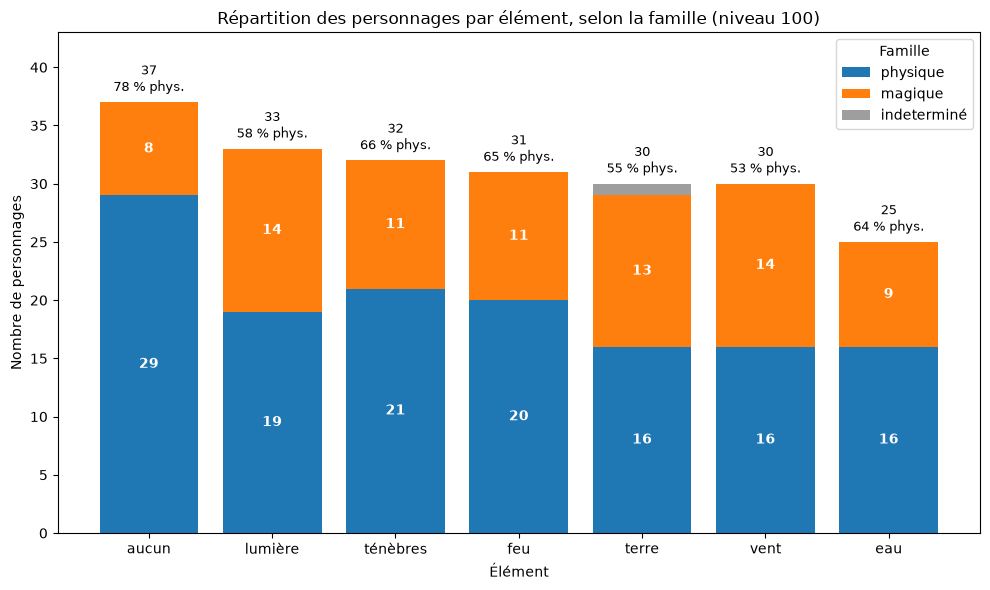

In [9]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]
FAMILLES = ["physique", "magique", "indetermine"]
COULEURS = {"physique": "#1f77b4", "magique": "#ff7f0e", "indetermine": "#9e9e9e"}

ELEMENTS = [r["element"] for r in
            df_perso_100.groupBy("element").count().orderBy(F.desc("count"), "element").collect()]

df_perso_100 = df_perso_100.withColumn(
    "faible_partout", (F.col("ATK") < 2300) & (F.col("MATK") < 2300)
)


tab = (
    df_perso_100.groupBy("element")
    .pivot("famille", FAMILLES).count().na.fill(0)
    .withColumn("total", F.col("physique") + F.col("magique") + F.col("indetermine"))
    .toPandas().set_index("element").loc[ELEMENTS]
)


fig, ax = plt.subplots(figsize=(10, 6))
bas = np.zeros(len(tab))
for fam in FAMILLES:
    ax.bar(tab.index, tab[fam], bottom = bas, color = COULEURS[fam], label=fam.replace("indetermine", "indeterminé"))

    for i, (v, b) in enumerate(zip(tab[fam], bas)):
        if v >= 3:                                  # pas d'étiquette dans un segment minuscule
            ax.text(i, b + v / 2, int(v), ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")
    bas += tab[fam].values

for i, (el, row) in enumerate(tab.iterrows()):
    pct = row["physique"] / (row["physique"] + row["magique"]) * 100
    ax.text(i, row["total"] + 0.6, f"{int(row['total'])}\n{pct:.0f} % phys.",
            ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, tab["total"].max() + 6)
ax.set_title("Répartition des personnages par élément, selon la famille (niveau 100)")
ax.set_xlabel("Élément")
ax.set_ylabel("Nombre de personnages")
ax.legend(title="Famille")
plt.tight_layout()
plt.show()

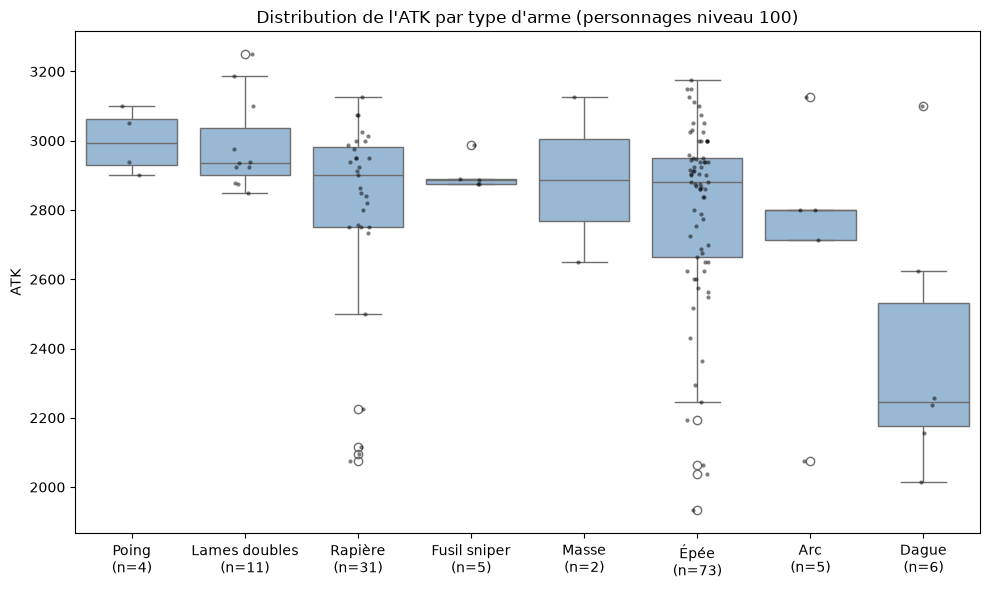

In [10]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "physique")
    .select("nom", "arme", "ATK")
    .toPandas()
)
ordre = pdf.groupby("arme")["ATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="ATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'ATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


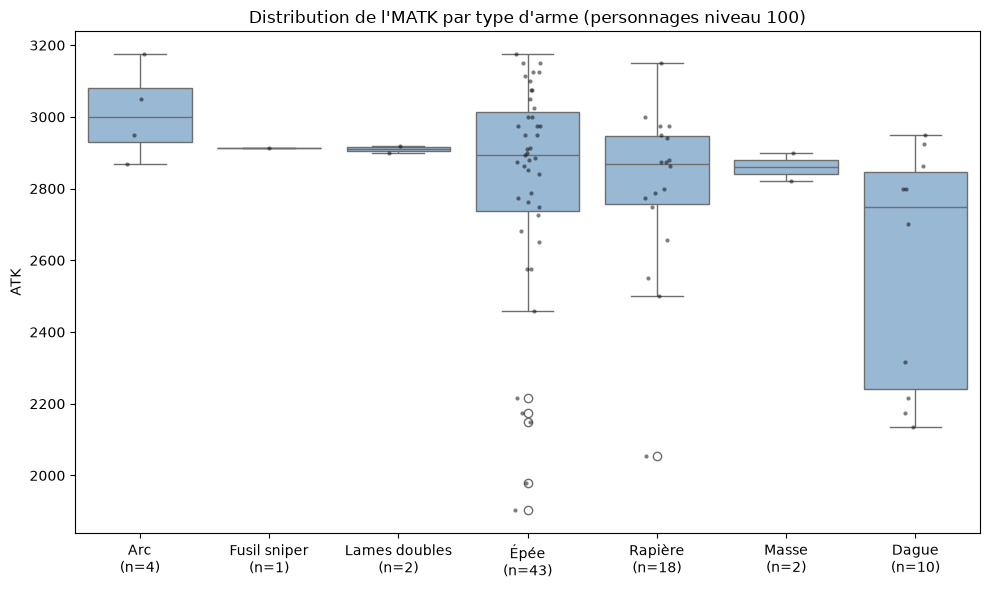

In [11]:
pdf = (
    df_perso_100
    .filter(F.col("famille") == "magique")
    .select("nom", "arme", "MATK")
    .toPandas()
)

ordre = pdf.groupby("arme")["MATK"].median().sort_values(ascending=False).index
effectifs = pdf["arme"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax, color="#8fb8de")
sns.stripplot(data=pdf, x="arme", y="MATK", order=ordre, ax=ax,
              color="black", size=3, alpha=0.5)

ax.set_xticks(range(len(ordre)))
ax.set_xticklabels([f"{a}\n(n={effectifs[a]})" for a in ordre])
ax.set_title("Distribution de l'MATK par type d'arme (personnages niveau 100)")
ax.set_xlabel("")
ax.set_ylabel("ATK")
plt.tight_layout()
plt.show()


### Graphique : Les stats

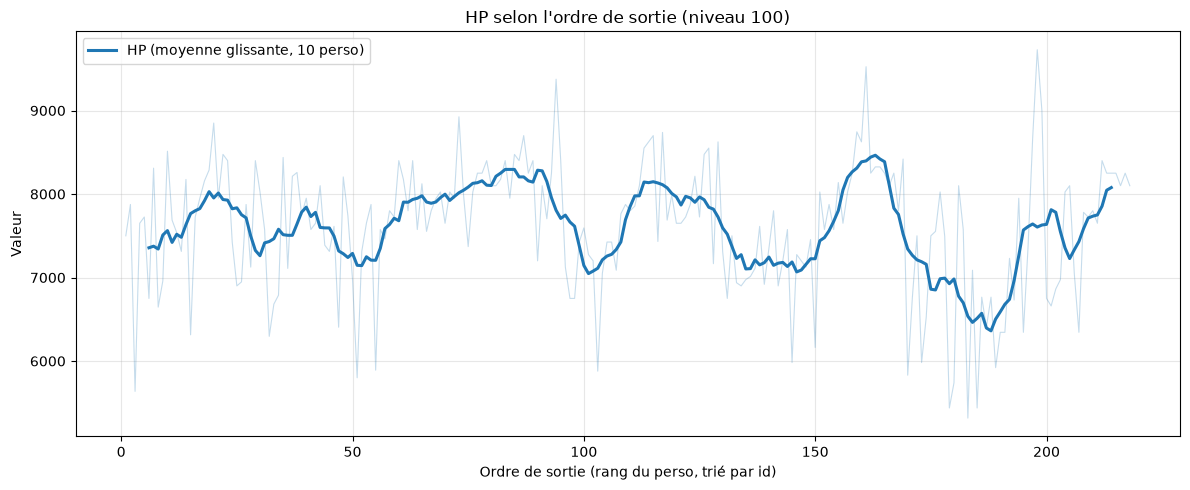

In [12]:
pdf = df_perso_100.select("id", "nom_complet", "HP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("HP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("HP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

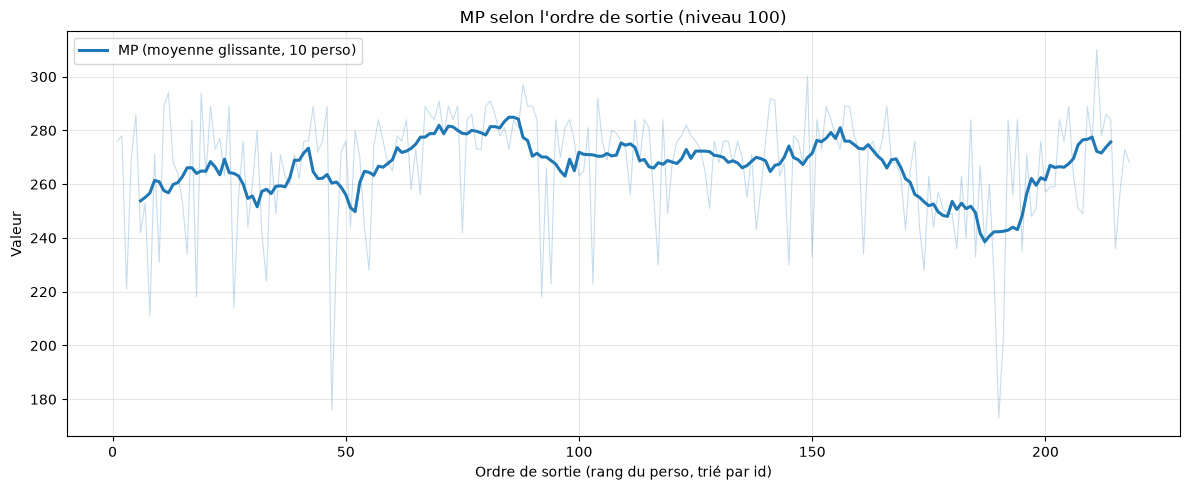

In [13]:
pdf = df_perso_100.select("id", "nom_complet", "MP").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("MP", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("MP selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

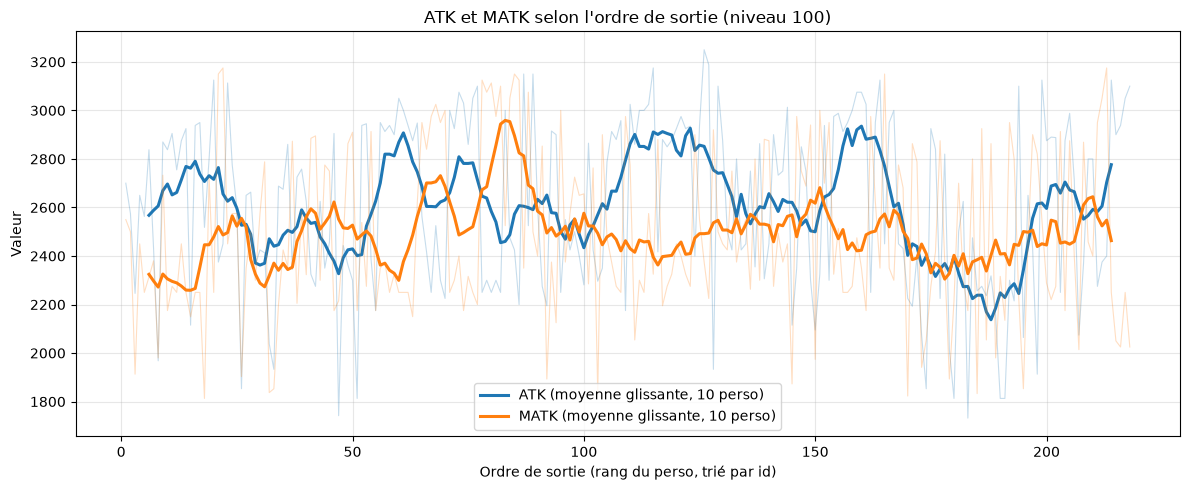

In [14]:
pdf = df_perso_100.select("id", "nom_complet", "ATK", "MATK").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("ATK", "#1f77b4"), ("MATK", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("ATK et MATK selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

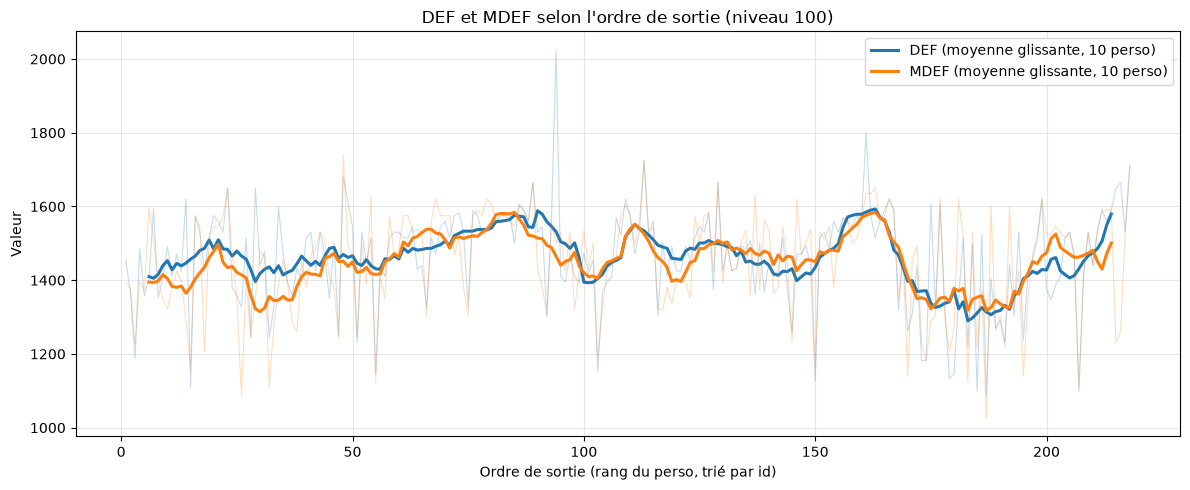

In [15]:
pdf = df_perso_100.select("id", "nom_complet", "DEF", "MDEF").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("DEF", "#1f77b4"), ("MDEF", "#ff7f0e")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("DEF et MDEF selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

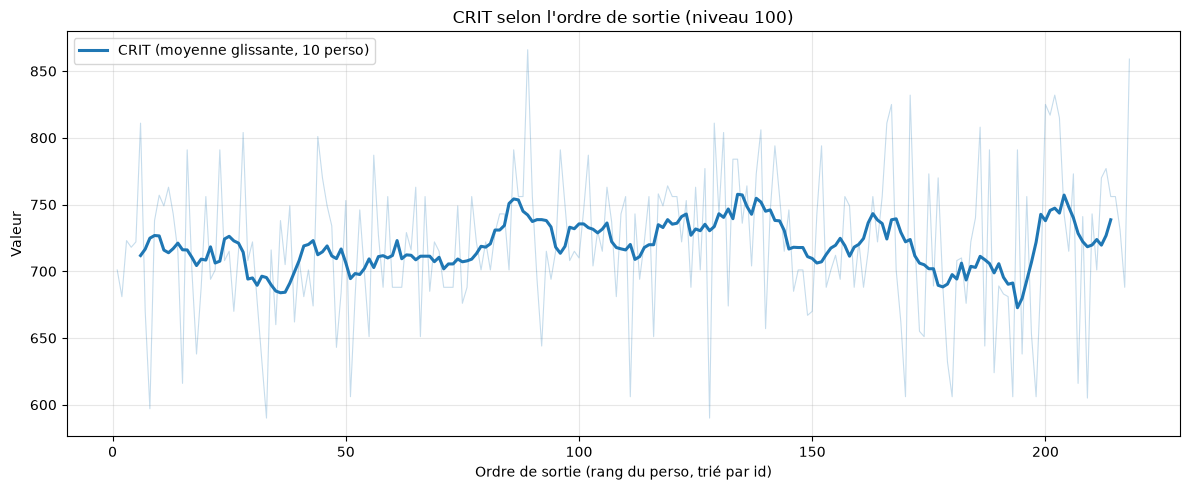

In [16]:
pdf = df_perso_100.select("id", "nom_complet", "CRIT").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("CRIT", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("CRIT selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

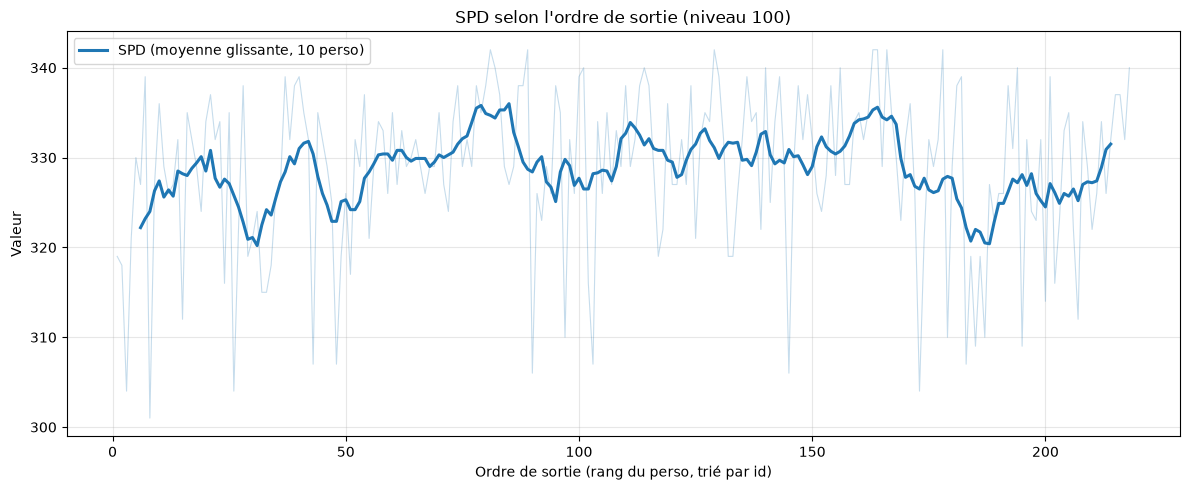

In [17]:
pdf = df_perso_100.select("id", "nom_complet", "SPD").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("SPD", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("SPD selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

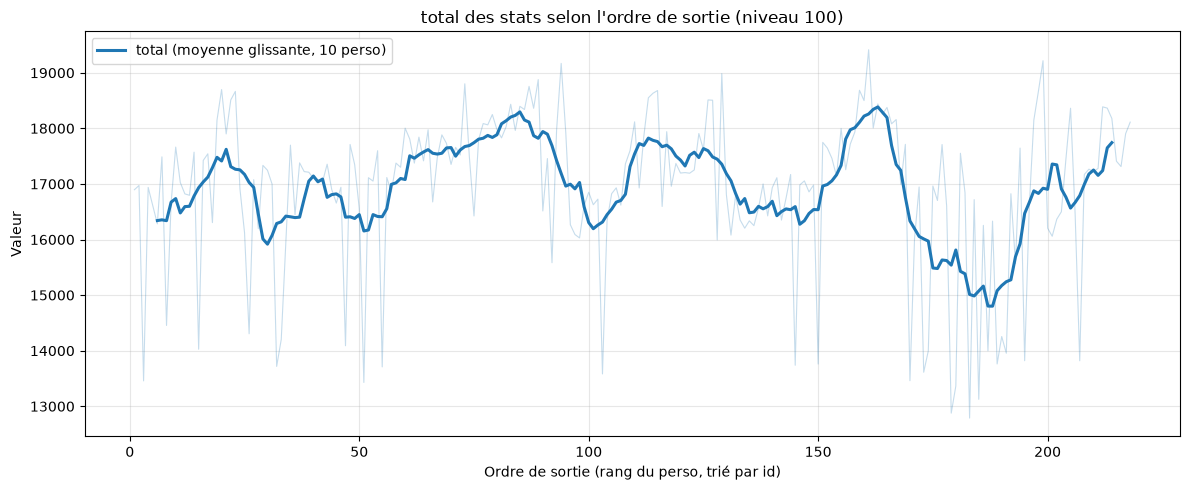



Comme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après



In [18]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

df_total = df_perso_100.withColumn("total" , sum(F.col(i) for i in STATS))


pdf = df_total.select("id", "nom_complet", "total").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("total", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n\nComme les HP représente environ 45% du total des stats, alors on normalise sur le graphique d'après\n")

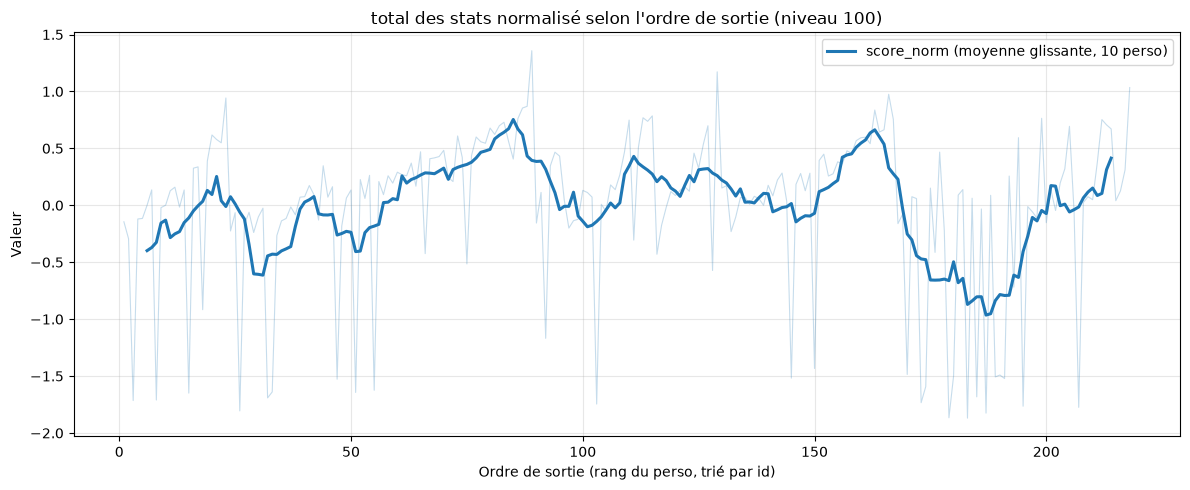

In [19]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT" ,"SPD"]

ms = df_perso_100.agg(
    *[F.avg(s).alias(f"{s}_moy") for s in STATS],
    *[F.stddev(s).alias(f"{s}_std") for s in STATS],
).first().asDict()

df_total = (
    df_perso_100
    .withColumn("total", sum(F.col(s) for s in STATS))
    .withColumn("score_norm",
        sum((F.col(s) - ms[f"{s}_moy"]) / ms[f"{s}_std"] for s in STATS) / len(STATS))
)

pdf = df_total.select("id", "nom_complet", "score_norm").orderBy("id").toPandas()

pdf["ordre"] = range(1, len(pdf)+1)

fig, ax = plt.subplots(figsize=(12, 5))

for stat, couleur in [("score_norm", "#1f77b4")]:
    # courbe brute, discrète
    ax.plot(pdf["ordre"], pdf[stat], color=couleur, alpha=0.25, linewidth=0.8)
    # courbe lissée, mise en avant
    ax.plot(pdf["ordre"], pdf[stat].rolling(10, center=True).mean(),
            color=couleur, linewidth=2.2,
            label=f"{stat} (moyenne glissante, 10 perso)")

ax.set_title("total des stats normalisé selon l'ordre de sortie (niveau 100)")
ax.set_xlabel("Ordre de sortie (rang du perso, trié par id)")
ax.set_ylabel("Valeur")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

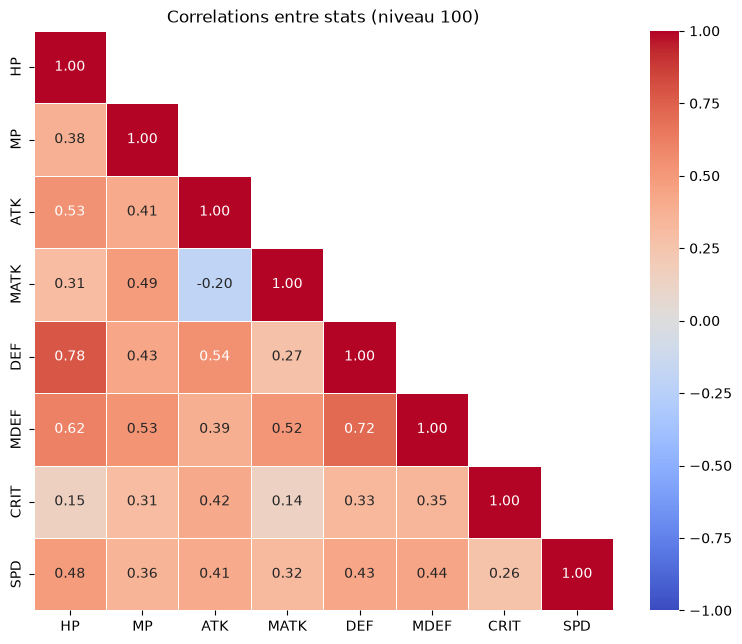

=== Paires classé ===


,stat_1,stat_2,r
6,DEF,HP,0.783372
14,MDEF,DEF,0.718355
10,MDEF,HP,0.615044
8,DEF,ATK,0.543190
1,ATK,HP,0.532094
11,MDEF,MP,0.527338
13,MDEF,MATK,0.517358
4,MATK,MP,0.489912
21,SPD,HP,0.484790
26,SPD,MDEF,0.438793


In [20]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def matrice_correlation(df, cols):
    paires = list(combinations(cols, 2))
    ligne = df.agg(*[F.corr(a, b).alias(f"{a}__{b}") for a, b in paires]).first()
    mat = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for a, b in paires:
        mat.loc[a, b] = mat.loc[b, a] = ligne[f"{a}__{b}"]
    return mat

corr = matrice_correlation(df_perso_100, STATS)

fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", vmin = -1, vmax=1, center = 0, square = True, linewidths=0.5, ax= ax)
ax.set_title("Correlations entre stats (niveau 100)")
plt.tight_layout()
plt.show()

print("=== Paires classé ===")
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

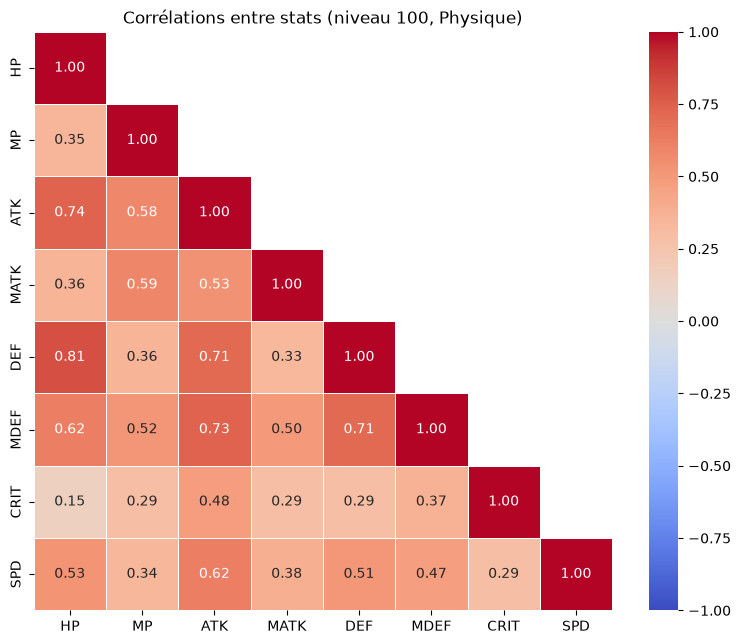

,stat_1,stat_2,r
6,DEF,HP,0.812464
1,ATK,HP,0.735340
12,MDEF,ATK,0.734913
8,DEF,ATK,0.711152
14,MDEF,DEF,0.710994
10,MDEF,HP,0.621900
23,SPD,ATK,0.619933
4,MATK,MP,0.591292
2,ATK,MP,0.582662
5,MATK,ATK,0.533137


In [21]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]


corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "physique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, Physique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

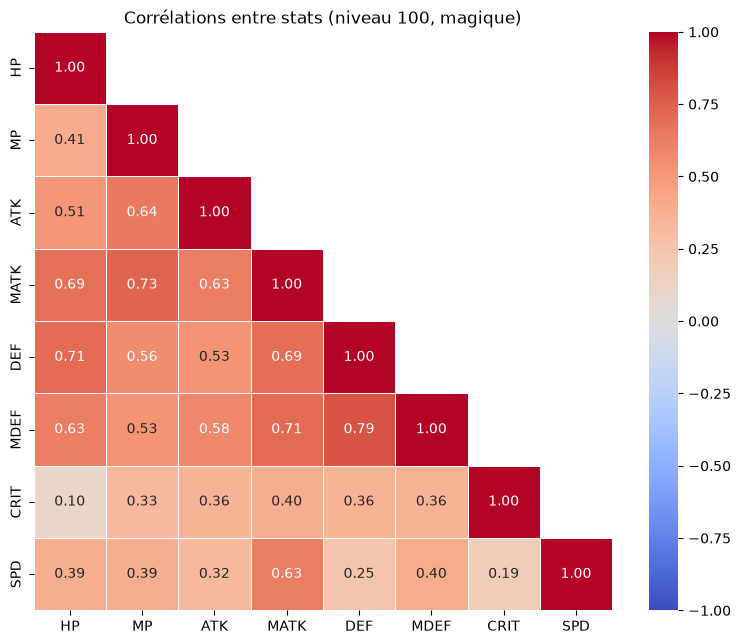

,stat_1,stat_2,r
14,MDEF,DEF,0.793625
4,MATK,MP,0.732303
13,MDEF,MATK,0.709808
6,DEF,HP,0.705460
9,DEF,MATK,0.694547
3,MATK,HP,0.687414
2,ATK,MP,0.641487
5,MATK,ATK,0.631977
10,MDEF,HP,0.629614
24,SPD,MATK,0.629130


In [22]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

corr = matrice_correlation(df_perso_100.filter(F.col("famille") == "magique"), STATS)

# Heatmap (triangle du bas seulement : la matrice est symétrique)
fig, ax = plt.subplots(figsize=(8, 6.5))
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Corrélations entre stats (niveau 100, magique)")
plt.tight_layout()
plt.show()

# Les paires classées, pour lire les chiffres sans la couleur
triangle = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
paires = triangle.stack().rename("r").reset_index()
paires.columns = ["stat_1", "stat_2", "r"]
paires.sort_values("r", key=abs, ascending=False)

=== Pas de corrélation entre les élément et les stats ===
--- le graph sert surtout à montrer qu'il n'y a pas de corrélation ---


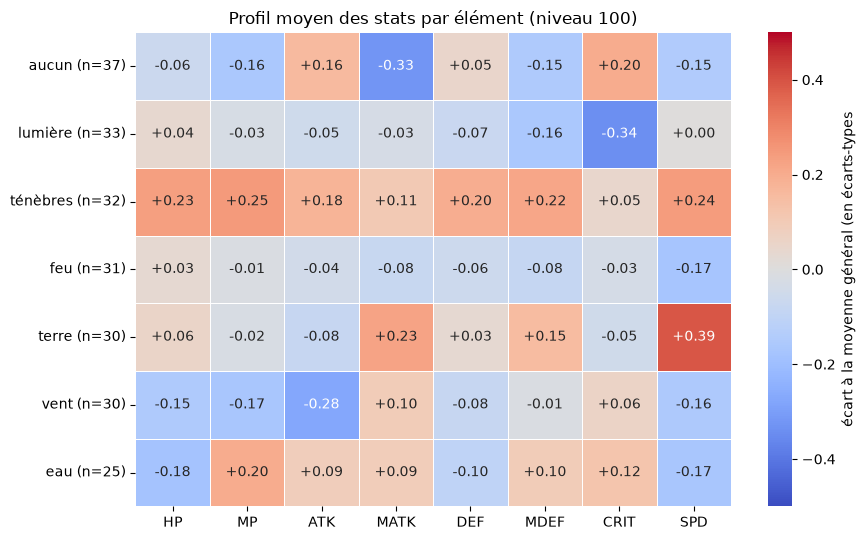

In [23]:
print("=== Pas de corrélation entre les élément et les stats ===\n--- le graph sert surtout à montrer qu'il n'y a pas de corrélation ---")

ms = df_perso_100.agg(
    *[F.avg(s).alias(f"{s}_moy") for s in STATS],
    *[F.stddev(s).alias(f"{s}_std") for s in STATS]
).first().asDict()

prof = (
    df_perso_100.groupBy("element")
    .agg(*[F.avg(s).alias(s) for s in STATS], F.count("*").alias("n"))
    .select("element", "n", *[((F.col(s) - ms[f"{s}_moy"]) / ms[f"{s}_std"]).alias(s) for s in STATS])
    .toPandas().set_index("element").loc[ELEMENTS]
)
labels = [f"{e} (n={int(prof.loc[e, 'n'])})" for e in prof.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(prof[STATS].set_axis(labels), annot=True, fmt="+.2f", cmap="coolwarm", vmin = -0.5, vmax=0.5, center = 0, linewidths = 0.5, ax=ax, cbar_kws={"label": "écart à la moyenne général (en écarts-types"})

ax.set_title("Profil moyen des stats par élément (niveau 100)")
plt.tight_layout()
plt.show()

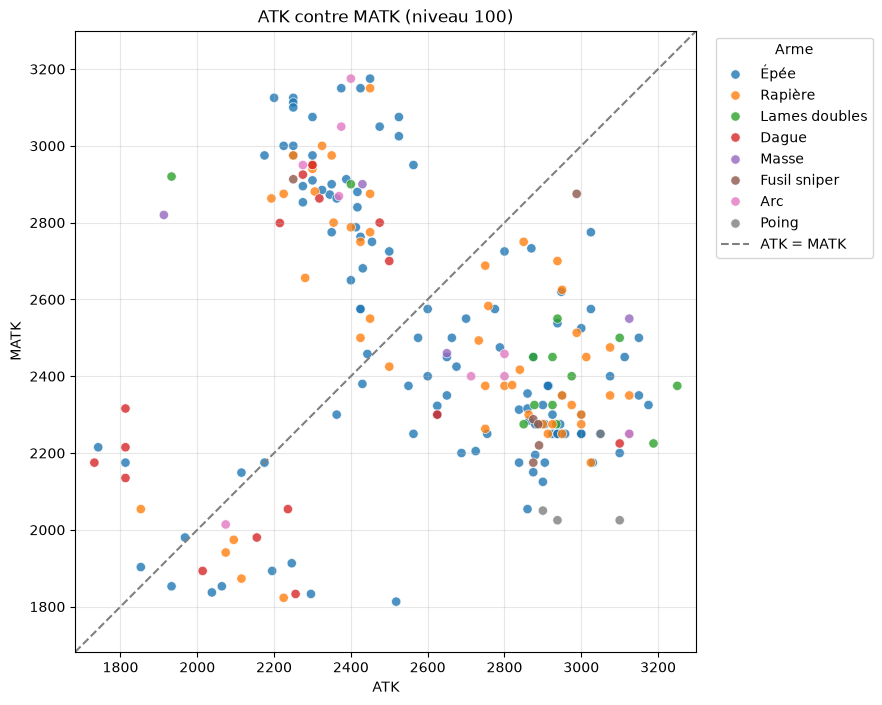

In [24]:
pdf = df_perso_100.select("nom_complet", "arme", "famille", "ATK", "MATK").toPandas()

fig, ax = plt.subplots(figsize=(8.5, 8))
sns.scatterplot(data=pdf, x="ATK", y = "MATK",hue = "arme",  ax = ax, s=45, alpha = 0.8, palette="tab10")

bas = pdf[["ATK", "MATK"]].min().min() - 50
haut = pdf[["ATK", "MATK"]].max().max() + 50
ax.plot([bas, haut], [bas, haut], linestyle="--", color="grey", label="ATK = MATK")

ax.set_xlim(bas, haut); ax.set_ylim(bas, haut)
ax.set_aspect("equal")                       # axes à la même échelle
ax.set_title("ATK contre MATK (niveau 100)")
ax.grid(alpha=0.3)
ax.legend(title="Arme", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Top 5 des meilleur et pire

In [25]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def top_5(df, stat, n=5):
    seuil_haut = (
        df.orderBy(F.desc(stat))
        .limit(n)
        .agg(F.min(stat))
        .first()[0]
    )

    seuil_bas = (
        df.orderBy(F.asc(stat))
        .limit(n)
        .agg(F.max(stat))
        .first()[0]
    )

    top = (
        df.filter(F.col(stat) >= seuil_haut)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.desc("valeur"), "nom_complet")
    )

    bot = (
        df.filter(F.col(stat) <= seuil_bas)
        .select("nom_complet", F.col(stat).alias("valeur"))
        .orderBy(F.asc("valeur"), "nom_complet")
    )

    return top, bot



for s in STATS:
    top, bot = top_5(df_perso_100, s)
    print(f"=== {s} : meilleur ===");   top.show(truncate=False)
    print(f"=== {s} : pires ===");  bot.show(truncate=False)
    print("--------------------------------------------------------\n")

=== HP : meilleur ===
+---------------------------------------------------+------+
|nom_complet                                        |valeur|
+---------------------------------------------------+------+
|[L'heure de fêter le Nouvel An] Lisbeth            |9728  |
|[Sous le ciel neigeux, les souvenirs] Administrator|9525  |
|[Le Chevalier aux bras de fer] Entokia             |9375  |
|[L'inébranlable Master Macer] Lisbeth              |9000  |
|[La déesse des abîmes] Eydis                       |8925  |
+---------------------------------------------------+------+

=== HP : pires ===
+----------------------------------------+------+
|nom_complet                             |valeur|
+----------------------------------------+------+
|[Le style qui me ressemble] Selka       |5317  |
|[La jeune fille du matin brumeux] Yui   |5438  |
|[Le style Serult d'une enfant] Soltirina|5438  |
|[L'éveil du héros] Kirito               |5637  |
|[Un souvenir d'enfance] Alice           |5740  |
+--------

### Les compétences

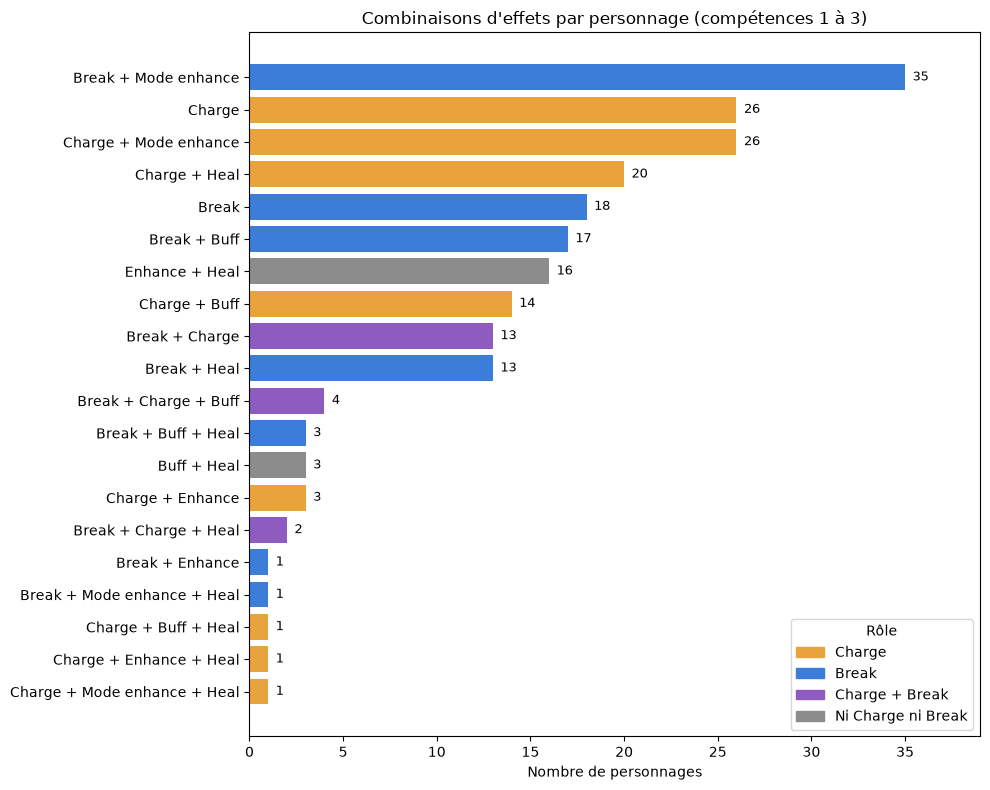

In [26]:
from functools import reduce

SLOTS = ["competence_1", "competence_2", "competence_3"]

def competence_slot(slot):
    c = F.col(f"competences.{slot}")
    return df_perso.select(
        F.col("id").alias("perso_id"),
        F.lit(slot).alias("slot"),
        c["categorie"].alias("categorie"),
        F.element_at(c["niveaux"], -1)["description"].alias("description"),   # dernier niveau
    )

df_comp = reduce(lambda a, b: a.unionByName(b), [competence_slot(s) for s in SLOTS])


BOOST = r"Capacité d'un allié à (charger|briser)"      # le vrai « Enhance »
cat, desc = F.col("categorie"), F.col("description")

def contient(motif):       # False (et non null) quand la description est vide
    return F.coalesce(desc.rlike(motif), F.lit(False))

TAGS = ["Break", "Charge", "Mode enhance", "Enhance", "Buff", "Heal"]

df_tags = df_comp.select(
    "perso_id",
    (contient(r"Brise la Volonté")     | cat.contains("BREAK")).alias("Break"),
    (contient(r"Charge la Volonté de") | cat.contains("CHARGE")).alias("Charge"),
    (cat == "ENHANCE_MODE").alias("Mode enhance"),
    contient(BOOST).alias("Enhance"),
    (cat.startswith("BUFF") & ~contient(BOOST)).alias("Buff"),
    (contient(r"Soins HP")             | cat.contains("HEAL")).alias("Heal"),
)

df_perso_tags = (
    df_tags.groupBy("perso_id")
    .agg(*[F.max(F.col(t).cast("int")).alias(t) for t in TAGS])     # 1 si au moins une compétence l'a
    .withColumn("combo", F.concat_ws(" + ", *[F.when(F.col(t) == 1, F.lit(t)) for t in TAGS]))
    .withColumn("combo", F.when(F.col("combo") == "", "(aucun)").otherwise(F.col("combo")))
    .withColumn("role",
        F.when((F.col("Charge") == 1) & (F.col("Break") == 1), "Charge + Break")
         .when(F.col("Charge") == 1, "Charge")
         .when(F.col("Break") == 1, "Break")
         .otherwise("Ni Charge ni Break"))
)


cnt = (df_perso_tags.groupBy("combo", "role").count()
       .orderBy(F.desc("count"), "combo").toPandas())

COULEURS_ROLE = {"Charge": "#e8a33d", "Break": "#3b7dd8",
                 "Charge + Break": "#8e5bc0", "Ni Charge ni Break": "#8c8c8c"}

cnt_plot = cnt.iloc[::-1]                       # le plus grand en haut
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(cnt_plot["combo"], cnt_plot["count"], color=cnt_plot["role"].map(COULEURS_ROLE))
for y, v in enumerate(cnt_plot["count"]):
    ax.text(v + 0.4, y, int(v), va="center", fontsize=9)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS_ROLE.values()]
ax.legend(handles, COULEURS_ROLE.keys(), title="Rôle", loc="lower right")
ax.set_title("Combinaisons d'effets par personnage (compétences 1 à 3)")
ax.set_xlabel("Nombre de personnages")
ax.set_xlim(0, cnt["count"].max() + 4)
plt.tight_layout()
plt.show()

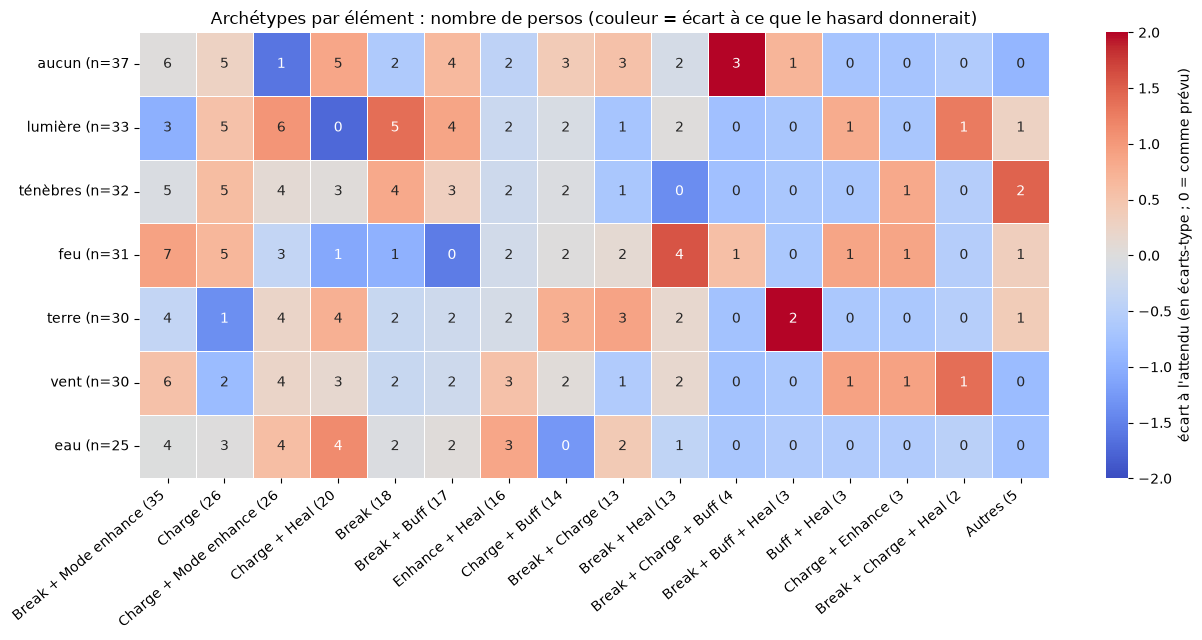

In [27]:
df_el = df_perso_tags.join(df_perso.select(F.col("id").alias("perso_id"), "element"), "perso_id")

N_TOP = 15
combos_top = [r["combo"] for r in
              df_el.groupBy("combo").count().orderBy(F.desc("count"), "combo").limit(N_TOP).collect()]

df_el = df_el.withColumn(
    "archetype", F.when(F.col("combo").isin(combos_top), F.col("combo")).otherwise("Autres")
)

colonnes = combos_top + ["Autres"]
tab = (
    df_el.groupBy("element").pivot("archetype", colonnes).count().na.fill(0).toPandas().set_index("element").loc[ELEMENTS, colonnes]
)

# Ce que le hasard donnerait si l'élément n'influençait pas l'archétype
attendu = pd.DataFrame(np.outer(tab.sum(axis=1), tab.sum(axis=0)) / tab.values.sum(), index=tab.index, columns=tab.columns)
ecart = (tab - attendu) / np.sqrt(attendu)

labels_lignes = [f"{e} (n={ int(tab.loc[e].sum()) }" for e in tab.index]
labels_cols = [f"{c} ({int(tab[c].sum())}" for c in tab.columns]

fig, ax = plt.subplots(figsize = (13, 6.5))
sns.heatmap(ecart.set_axis(labels_lignes).set_axis(labels_cols, axis=1), annot=tab.values, fmt="d", cmap="coolwarm", vmin=-2, vmax = 2, center=0, linewidths=0.5, ax=ax, cbar_kws={"label": "écart à l'attendu (en écarts-type ; 0 = comme prévu)"})
ax.set_title("Archétypes par élément : nombre de persos (couleur = écart à ce que le hasard donnerait)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

+---+
|p  |
+---+
+---+



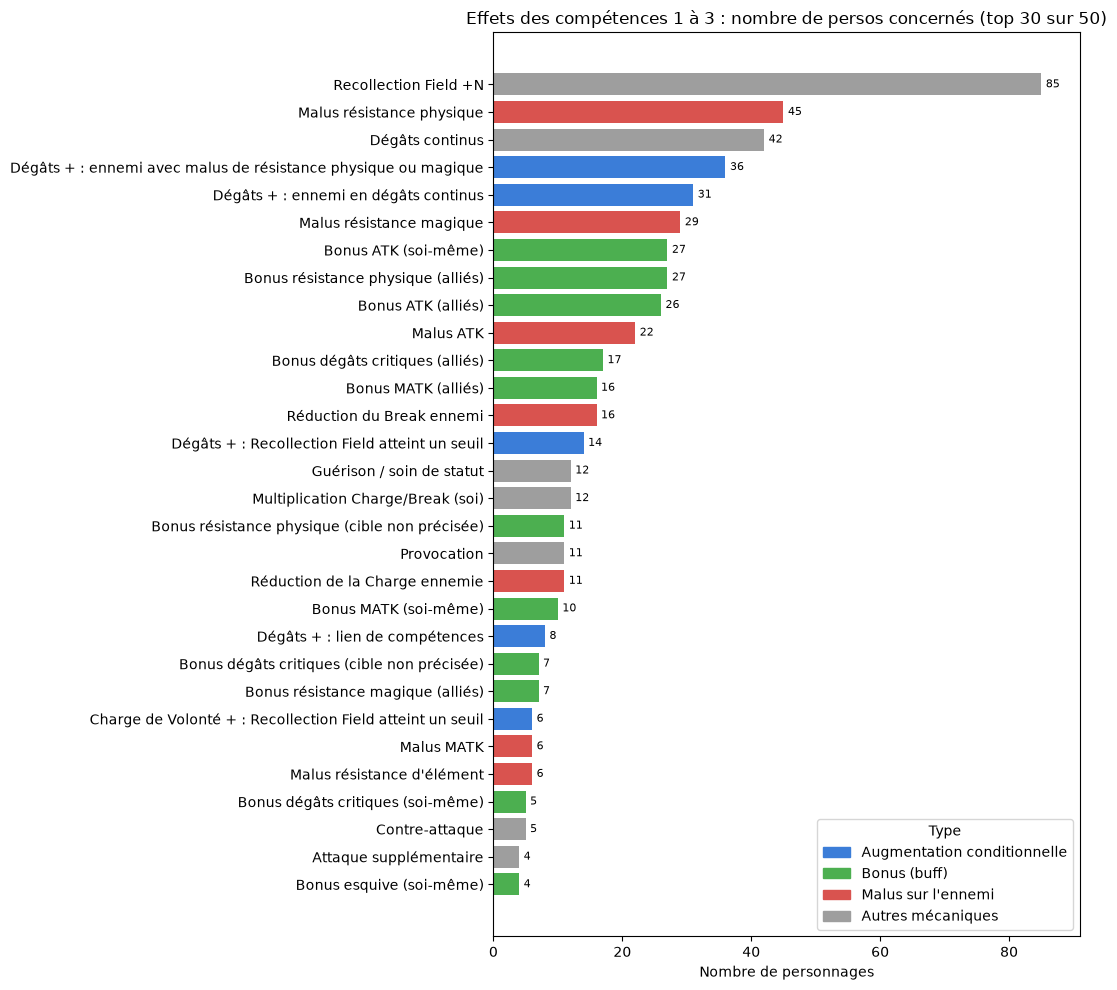

In [28]:
SLOTS = ["competence_1", "competence_2", "competence_3"]      #
# ["incarnation"] pour la section dédiée

def phrases_du_slot(slot):
    c = F.col(f"competences.{slot}")
    return df_perso.select(
        F.col("id").alias("perso_id"), "element", F.lit(slot).alias("slot"),
        F.element_at(c["niveaux"], -1)["description"].alias("description"),   # niveau max
    )

SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"

def normaliser(col):
    c = F.regexp_replace(col, r"tour\(s\)", "tours")
    c = F.regexp_replace(c, r"\s*\([^()]*(tours|maximum)[^()]*\)", "")      # durées et « maximum »
    c = F.regexp_replace(c, r"\s*\((faible|moyenne|forte|énorme)\)", "")    # intensités
    c = F.regexp_replace(c, r"\d+(,\d+)?", "N")                             # nombres
    c = F.regexp_replace(c, r"\s+", " ")
    c = F.regexp_replace(c, r"[\s.,;]+$", "")
    return F.trim(c)

EXCLUS = (r"^(Brise la Volonté|Charge la Volonté de|Entre soi-même en mode|Capacité d'un allié|Soins HP"
          r"|Attaque (tranchante|magique|perçante|de frappe) sur (un ennemi|tous les ennemis)$"
          r"|Temps de préparation|Rotation|\（仮\）|$)")

df_phr = (
    reduce(lambda a, b: a.unionByName(b), [phrases_du_slot(s) for s in SLOTS])
    .select("perso_id", "element", "slot", F.explode(F.split(F.trim("description"), SPLIT)).alias("phrase"))
    .withColumn("p", normaliser(F.col("phrase")))
    .filter(~F.col("p").rlike(EXCLUS))
)


p = F.col("p")
vide = F.array().cast("array<string>")

# a) « Augmentation de … » : effet augmenté + condition (inchangé)
est_boost = p.rlike(r"^Augmentation (des dégâts|de la Charge de Volonté|de la capacité à briser|du Break de Volonté)")
effet_boost = (F.when(p.rlike(r"^Augmentation des dégâts"), "Dégâts")
                .when(p.rlike(r"^Augmentation de la Charge"), "Charge de Volonté")
                .otherwise("Break de Volonté"))
condition = (
    F.when(p.contains("subissant des dégâts continus"), "ennemi en dégâts continus")
     .when(p.contains("subissant un malus de résistance"),
           F.concat(F.lit("ennemi avec malus de résistance "),
                    F.regexp_extract(p, r"malus de résistance\s*(.*)$", 1)))
     .when(p.contains("Recollection Field"), "Recollection Field atteint un seuil")
     .when(p.contains("lien de compétences"), "lien de compétences")
     .when(p.contains("nombre de cibles"), "nombre de cibles")
     .when(p.rlike(r"(quand|lorsque) le bonus"), "bonus d'ATK ou de critique atteint un seuil")
     .otherwise("autre condition")
)
etiq_boost = F.when(est_boost, F.array(F.concat(effet_boost, F.lit(" + : "), condition))).otherwise(vide)

# Toutes les règles qui correspondent, pas seulement la première
def correspondances(regles):
    return F.filter(F.array(*[F.when(p.rlike(r), F.lit(n)) for r, n in regles]),
                    lambda x: x.isNotNull())

# b) Effets sans cible
REGLES = [
    (r"^Résistances? physique( et magique)? -N%", "Malus résistance physique"),
    (r"^Résistance magique (sur l'ennemi )?-N%|^Résistances? physique et magique -N%"
     r"|^Résistance physique -N% et résistance magique -N%", "Malus résistance magique"),
    (r"^Résistance à l'élément [^ ]+ -N%|^La résistance à l'élément [^ ]+ diminue"
     r"|et de N% la résistance à l'élément", "Malus résistance d'élément"),
    (r"^De plus, DEF et MDEF -N% si l'ennemi", "Malus DEF et MDEF (ennemi d'un élément)"),
    (r"^ATK -N%", "Malus ATK"),
    (r"^MATK -N%", "Malus MATK"),
    (r"^Réduit de N% le Break de Volonté de l'ennemi", "Réduction du Break ennemi"),
    (r"^Réduit (de N% )?la Charge de Volonté (ennemie|de l'ennemi)|^Charge de Volonté de l'ennemi -N%", "Réduction de la Charge ennemie"),
    (r"^Inflige des dégâts continus", "Dégâts continus"),
    (r"^Recollection Field", "Recollection Field +N"),
    (r"^Provoque l'ennemi", "Provocation"),
    (r"^Inflige une contre-attaque", "Contre-attaque"),
    (r"^(Guérit|Soigne|Guérison)", "Guérison / soin de statut"),
    (r"^Multiplie (sa|le|la) |^Capacité à charger", "Multiplication Charge/Break (soi)"),
    (r"^Attaque .*N% de dégâts de HP maximum", "Attaque avec coût en HP"),
    (r"^Et attaque ", "Attaque supplémentaire"),
    (r"^En contrepartie|^Résistance [^ ]+ sur soi-même -N%", "Malus en contrepartie"),
]

# c) Bonus : on cherche chaque stat citée dans la phrase
BONUS = [
    (r"(?<![A-Za-z])ATK", "Bonus ATK"),                 # pas de « M » devant : MATK est à part
    (r"MATK", "Bonus MATK"),
    (r"[Rr]ésistances? physique", "Bonus résistance physique"),
    (r"[Rr]ésistances? (physique et )?magique", "Bonus résistance magique"),
    (r"[Rr]ésistance (d'|à l')élément", "Bonus résistance d'élément"),
    (r"[Dd]égâts critiques", "Bonus dégâts critiques"),
    (r"Taux de coup critique", "Bonus taux de critique"),
    (r"Taux d'esquive", "Bonus esquive"),
]
cible = (F.when(p.contains("soi-même"), " (soi-même)")
          .when(p.rlike("alliés?"), " (alliés)")
          .otherwise(" (cible non précisée)"))
est_bonus = ~est_boost & p.rlike(r"\+N%|en augmentant de N%|^Augmentation de N% des dégâts critiques")
etiq_bonus = F.when(est_bonus,
                    F.transform(correspondances(BONUS), lambda n: F.concat(n, cible))).otherwise(vide)

# Une ligne par effet (une phrase peut en avoir plusieurs)
toutes = F.concat(etiq_boost, correspondances(REGLES), etiq_bonus)
df_eff = (df_phr
          .withColumn("effets", F.when(F.size(toutes) == 0, F.array(F.lit("Autre"))).otherwise(toutes))
          .withColumn("effet", F.explode("effets"))
          .drop("effets"))

df_eff.filter(F.col("effet") == "Autre").select("p").distinct().show(truncate=False)   # doit être vide


global_ = (df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb_persos"))
           .orderBy(F.desc("nb_persos"), "effet").toPandas())

def categorie(e):
    if " + : " in e: return "Augmentation conditionnelle"
    if e.startswith("Bonus"): return "Bonus (buff)"
    if e.startswith(("Malus", "Réduction")): return "Malus sur l'ennemi"
    return "Autres mécaniques"

COUL = {"Augmentation conditionnelle": "#3b7dd8", "Bonus (buff)": "#4caf50",
        "Malus sur l'ennemi": "#d9534f", "Autres mécaniques": "#9e9e9e"}

N_AFF = 30
g = global_.head(N_AFF).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(g["effet"], g["nb_persos"], color=g["effet"].map(lambda e: COUL[categorie(e)]))
for y, v in enumerate(g["nb_persos"]):
    ax.text(v + 0.7, y, int(v), va="center", fontsize=8)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COUL.values()], COUL.keys(),
          title="Type", loc="lower right")
ax.set_title(f"Effets des compétences 1 à 3 : nombre de persos concernés (top {N_AFF} sur {len(global_)})")
ax.set_xlabel("Nombre de personnages")
ax.set_xlim(0, g["nb_persos"].max() + 6)
plt.tight_layout()
plt.show()

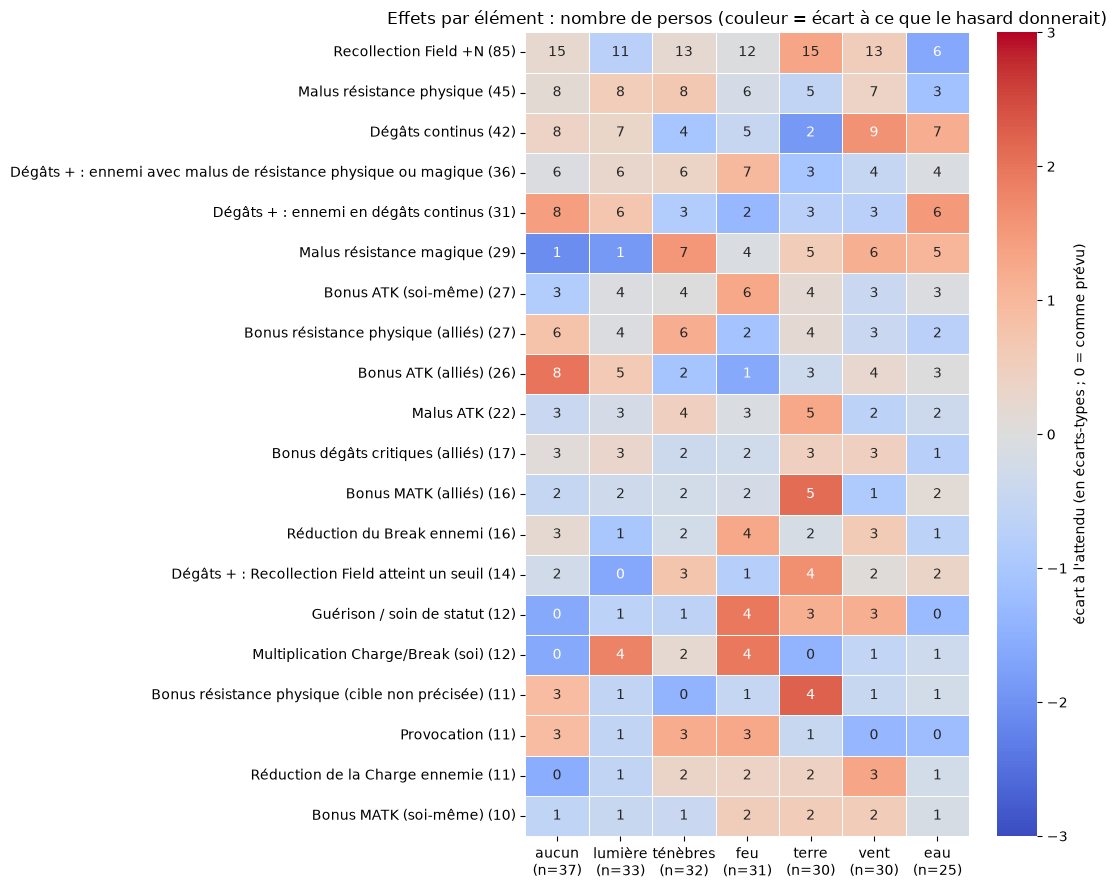

In [29]:
MIN_PERSOS = 10
effets_top = [r["effet"] for r in
              df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb"))
              .filter(F.col("nb") >= MIN_PERSOS)
              .orderBy(F.desc("nb"), "effet").collect()]
n_el = df_perso.groupBy("element").count().toPandas().set_index("element")["count"].loc[ELEMENTS]
N = int(n_el.sum())

cnt = (df_eff.filter(F.col("effet").isin(effets_top)).select("perso_id", "element", "effet").distinct()
       .groupBy("effet").pivot("element", ELEMENTS).count().na.fill(0)
       .toPandas().set_index("effet").loc[effets_top, ELEMENTS])

# Écart à l'attendu, en écarts-types (loi hypergéométrique)
k = cnt.sum(axis=1)
pp = (k / N).values[:, None]
attendu = pp * n_el.values[None, :]
var = n_el.values[None, :] * pp * (1 - pp) * (N - n_el.values[None, :]) / (N - 1)
z = pd.DataFrame((cnt.values - attendu) / np.sqrt(var), index=cnt.index, columns=cnt.columns)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(z.set_axis([f"{e} ({int(k[e])})" for e in z.index])
             .set_axis([f"{c}\n(n={n_el[c]})" for c in z.columns], axis=1),
            annot=cnt.values, fmt="d", cmap="coolwarm", vmin=-3, vmax=3, center=0,
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "écart à l'attendu (en écarts-types ; 0 = comme prévu)"})
ax.set_title("Effets par élément : nombre de persos (couleur = écart à ce que le hasard donnerait)")
plt.tight_layout()
plt.show()

In [30]:
print("persos « Bonus dégâts critiques (alliés) » :",
      df_eff.filter(F.col("effet") == "Bonus dégâts critiques (alliés)")
            .select("perso_id").distinct().count())
print("len(global_) :", len(global_))

# Ton perso eau, directement
(df_eff.filter(F.col("perso_id") == 130124039)
       .select("slot", "effet").distinct().orderBy("slot", "effet")
       .show(truncate=False))

persos « Bonus dégâts critiques (alliés) » : 17
len(global_) : 50
+------------+-------------------------------+
|slot        |effet                          |
+------------+-------------------------------+
|competence_1|Malus résistance physique      |
|competence_1|Recollection Field +N          |
|competence_2|Bonus ATK (alliés)             |
|competence_2|Bonus dégâts critiques (alliés)|
|competence_3|Bonus ATK (alliés)             |
|competence_3|Bonus dégâts critiques (alliés)|
+------------+-------------------------------+



In [31]:
SLOTS_COMPETENCES = ["competence_1", "competence_2", "competence_3"]
SLOTS_INCARNATION = ["incarnation"]

ELEMENTS = [r["element"] for r in
            df_perso.groupBy("element").count().orderBy(F.desc("count"), "element").collect()]

SPLIT = r"(?<=\.)\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ])"

# Phrases déjà traitées ailleurs (Break, Charge, Mode enhance, Enhance, Heal) ou sans intérêt ici
EXCLUS = (r"^(Brise la Volonté|Charge la Volonté de|Entre soi-même en mode|Capacité d'un allié|Soins HP"
          r"|Attaque (tranchante|magique|perçante|de frappe)( de Volonté)?( à puissance énorme)? sur (un ennemi|tous les ennemis)$"
          r"|Temps de préparation|Rotation|\（仮\）|$)")

# ----------------------------------------------------------------------------------------------
# Règles de regroupement
# ----------------------------------------------------------------------------------------------
REGLES = [
    (r"^Résistances? physique( et magique)? -N%", "Malus résistance physique"),
    (r"^Résistance magique (sur l'ennemi )?-N%|^Résistances? physique et magique -N%"
     r"|^Résistance physique -N% et résistance magique -N%", "Malus résistance magique"),
    (r"^Résistance à l'élément [^ ]+ -N%|^La résistance à l'élément [^ ]+ diminue"
     r"|et de N% la résistance à l'élément", "Malus résistance d'élément"),
    (r"^De plus, DEF et MDEF -N% si l'ennemi", "Malus DEF et MDEF (ennemi d'un élément)"),
    (r"^ATK -N%", "Malus ATK"),
    (r"^MATK -N%", "Malus MATK"),
    (r"^MP -N% pour l'élément", "Malus MP selon l'élément"),
    (r"^Élément [^ ]+ -N% sur l'ennemi", "Malus d'élément sur l'ennemi"),
    (r"^Réduit de N% le Break de Volonté de l'ennemi", "Réduction du Break ennemi"),
    (r"^Réduit de N% le Break de la compétence ennemie", "Réduction du Break de la compétence ennemie"),
    (r"^Réduit (de N% )?la Charge de Volonté (ennemie|de l'ennemi)|^Charge de Volonté de l'ennemi -N%", "Réduction de la Charge ennemie"),
    (r"^Inflige des dégâts continus", "Dégâts continus"),
    (r"^Provoque l'ennemi", "Provocation"),
    (r"^Inflige une contre-attaque", "Contre-attaque"),
    (r"^(Guérit|Soigne|Guérison)", "Guérison / soin de statut"),
    (r"^Restauration de MP", "Restauration de MP (alliés)"),
    (r"^Absorption des HP", "Absorption de HP"),
    (r"^Multiplie (sa|le|la) |^Capacité à charger", "Multiplication Charge/Break (soi)"),
    (r"^Attaque .*N% de dégâts de HP maximum", "Attaque avec coût en HP"),
    (r"^Et attaque ", "Attaque supplémentaire"),
    (r"^En contrepartie|^Résistance [^ ]+ sur soi-même -N%", "Malus en contrepartie"),
]

BONUS = [
    (r"(?<![A-Za-z])ATK", "Bonus ATK"),                  # pas de lettre devant : MATK est à part
    (r"MATK", "Bonus MATK"),
    (r"[Rr]ésistances? physique", "Bonus résistance physique"),
    (r"[Rr]ésistances? (physique et )?magique", "Bonus résistance magique"),
    (r"[Rr]ésistance (d'|à l')élément", "Bonus résistance d'élément"),
    (r"[Dd]égâts critiques", "Bonus dégâts critiques"),
    (r"Taux de coup critique", "Bonus taux de critique"),
    (r"Taux d'esquive", "Bonus esquive"),
]

# ----------------------------------------------------------------------------------------------
# Construction de la table des effets (une ligne par perso, compétence et effet)
# ----------------------------------------------------------------------------------------------

def normaliser(col):
    c = F.regexp_replace(col, "’", "'")                                      # apostrophe typographique
    c = F.regexp_replace(c, r"tour\(s\)", "tours")
    c = F.regexp_replace(c, r"\s*\([^()]*(tours|maximum)[^()]*\)", "")        # durées et « maximum »
    c = F.regexp_replace(c, r"\s*\((faible|moyenne|forte|énorme)\)", "")      # intensités
    c = F.regexp_replace(c, r"\d+(,\d+)?", "N")                               # nombres
    c = F.regexp_replace(c, r"\s+", " ")
    c = F.regexp_replace(c, r"[\s.,;]+$", "")
    return F.trim(c)

def construire_effets(slots):
    def phrase_du_slot(slot):
        c = F.col(f"competences.{slot}")
        return df_perso.select(
            F.col("id").alias("perso_id"), "element", F.lit(slot).alias("slot"),
            F.element_at(c["niveau"], -1)["desciption"].alias('description')
        )
    df_phr = (
        reduce(lambda a, b:a.unionByName(b), [phrases_du_slot(s) for s in slots])
        .select("perso_id", "element", "slot", F.explode(F.split(F.trim("description"), SPLIT)).alias("phrase"))
        .withColumn("p", normaliser(F.col("phrase")))
        .filter(~F.col("p").rlike(EXCLUS))
    )

    p = F.col("p")
    vide = F.array().cast("array<string>")

    def correspondancec(regles):
        return F.filter(F.array(*[F.when(p.rlike(r), F.lit(n)) for r, n in regles]), lambda x: x.isNotNull())

    # a) Recollection Field : la valeur (+1, +2, +3) se lit dans le texte d'origine (colonne « phrase »)
    est_rf = p.rlike(r"^Recollection Field")
    rf_valeur = F.regexp_extract(F.col("phrase"), r"^Recollection Field(?: spécial)? \([^)]*\)\s*\+(\d+)", 1)
    etiq_rf = (
        F.when(p.rlike(r"^Recollection Field spécial"),
               F.array(F.concat(F.lit("Recollection Field spécial +"), rf_valeur)))
         .when(est_rf, F.array(F.concat(F.lit("Recollection Field +"), rf_valeur)))
         .otherwise(vide)
    )

    # b) « Augmentation de … » : effet augmenté + condition
    est_boost = ~est_rf & p.rlike(
        r"[Aa]ugmentation (de N% )?(des dégâts(?! critiques)|de la Charge de Volonté|de la capacité à briser|du Break de Volonté)"
        r"|^Augmente les dégâts(?! critiques)|^Lance sur tous les alliés un bonus augmentant les dégâts")
    effet_boost = (
        F.when(p.rlike(r"[Aa]ugmentation (de N% )?des dégâts(?! critiques)|^Augmente les dégâts(?! critiques)|bonus augmentant les dégâts"), "Dégâts")
         .when(p.rlike(r"[Aa]ugmentation de la Charge"), "Charge de Volonté")
         .otherwise("Break de Volonté")
    )
    condition = (
        F.when(p.contains("subissant des dégâts continus"), "ennemi en dégâts continus")
         .when(p.contains("subissant un malus de résistance"),
               F.concat(F.lit("ennemi avec malus de résistance "),
                        F.regexp_extract(p, r"malus de résistance\s*(.*)$", 1)))
         .when(p.contains("Recollection Field"), "Recollection Field atteint un seuil")
         .when(p.contains("lien de compétences"), "lien de compétences")
         .when(p.contains("nombre de cibles"), "nombre de cibles")
         .when(p.rlike(r"Volonté de l'ennemi (dépasse|est de N% ou plus)"), "Volonté ennemie au-dessus d'un seuil")
         .when(p.rlike(r"(quand|lorsque) le bonus"), "bonus d'ATK ou de critique atteint un seuil")
         .otherwise("autre condition")
    )
    etiq_boost = F.when(est_boost, F.array(F.concat(effet_boost, F.lit(" + : "), condition))).otherwise(vide)

    # c) Bonus : on cherche chaque stat citée dans la phrase, la cible est ajoutée une seule fois
    cible = (F.when(p.contains("soi-même"), " (soi-même)")
              .when(p.rlike("alliés?"), " (alliés)")
              .otherwise(" (cible non précisée)"))
    est_bonus = ~est_boost & ~est_rf & p.rlike(
        r"\+N%|en augmentant de N%|en augmentant l'(ATK|MATK) de N%"
        r"|^Augmentation de N% des dégâts critiques|^Augmente les dégâts critiques de N%")
    etiq_bonus = F.when(est_bonus,
                        F.transform(correspondances(BONUS), lambda n: F.concat(n, cible))).otherwise(vide)

    # d) Assemblage : une phrase peut avoir plusieurs effets ; sans aucun effet reconnu -> « Autre »
    toutes = F.concat(etiq_rf, etiq_boost, correspondances(REGLES), etiq_bonus)
    df_eff = (df_phr
              .withColumn("effets", F.when(F.size(toutes) == 0, F.array(F.lit("Autre"))).otherwise(toutes))
              .withColumn("effet", F.explode("effets"))
              .drop("effets"))

    autres = df_eff.filter(F.col("effet") == "Autre").select("p").distinct().collect()
    print(f"{slots} : {df_eff.select('effet').distinct().count()} effets distincts | "
          f"phrases non classées (« Autre ») : {len(autres)}")
    for r in autres:
        print("   non classée :", r["p"])
    return df_eff


# ----------------------------------------------------------------------------------------------
# Graphiques
# ----------------------------------------------------------------------------------------------
COUL = {"Recollection Field": "#e0a800", "Augmentation conditionnelle": "#3b7dd8",
        "Bonus (buff)": "#4caf50", "Malus sur l'ennemi": "#d9534f",
        "Autres mécaniques": "#9e9e9e", "Non classé": "#333333"}

def categorie(e):
    if e.startswith("Recollection Field"): return "Recollection Field"
    if " + : " in e: return "Augmentation conditionnelle"
    if e.startswith("Bonus"): return "Bonus (buff)"
    if e == "Autre": return "Non classé"
    if e.startswith(("Malus", "Réduction")) and e != "Malus en contrepartie": return "Malus sur l'ennemi"
    return "Autres mécaniques"

def graphique_global(df_eff, titre):
    """Nombre de persos par effet : TOUS les effets sont affichés."""
    g = (df_eff.groupBy("effet").agg(F.countDistinct("perso_id").alias("nb_persos"))
         .orderBy(F.desc("nb_persos"), "effet").toPandas())
    g = g.iloc[::-1]                                              # le plus grand en haut
    fig, ax = plt.subplots(figsize=(11, max(5, 0.30 * len(g) + 1.5)))
    ax.barh(g["effet"], g["nb_persos"], color=g["effet"].map(lambda e: COUL[categorie(e)]))
    for y, v in enumerate(g["nb_persos"]):
        ax.text(v + g["nb_persos"].max() * 0.008, y, int(v), va="center", fontsize=8)
    for lbl in ax.get_yticklabels():                              # les Recollection Field ressortent
        if lbl.get_text().startswith("Recollection Field"):
            lbl.set_fontweight("bold")
    presentes = [c for c in COUL if c in set(g["effet"].map(categorie))]
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=COUL[c]) for c in presentes], presentes,
              title="Type", loc="lower right")
    ax.set_title(f"{titre}\n(nombre de persos concernés, {len(g)} effets)")
    ax.set_xlabel("Nombre de personnages")
    ax.set_xlim(0, g["nb_persos"].max() * 1.08)
    plt.tight_layout()
    plt.show()
    return g.iloc[::-1].reset_index(drop=True)

def graphique_par_element(df_eff, titre, seuil_couleur=10):
    """Persos par effet et par élément : TOUS les effets sont affichés.
    La couleur (écart à l'attendu) n'est calculée que pour les effets d'au moins `seuil_couleur` persos."""
    n_el = df_perso.groupBy("element").count().toPandas().set_index("element")["count"].loc[ELEMENTS]
    N = int(n_el.sum())
    cnt = (df_eff.select("perso_id", "element", "effet").distinct()
           .groupBy("effet").pivot("element", ELEMENTS).count().na.fill(0)
           .toPandas().set_index("effet")[ELEMENTS])
    cnt["_k"] = cnt.sum(axis=1)
    cnt = cnt.loc[sorted(cnt.index, key=lambda e: (-cnt.loc[e, "_k"], e))]    # plus fréquents d'abord
    k = cnt.pop("_k")

    pp = (k / N).values[:, None]
    attendu = pp * n_el.values[None, :]
    var = n_el.values[None, :] * pp * (1 - pp) * (N - n_el.values[None, :]) / (N - 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        z = pd.DataFrame((cnt.values - attendu) / np.sqrt(var), index=cnt.index, columns=cnt.columns)
    z = z.fillna(0)
    z.loc[k < seuil_couleur] = 0                                  # trop peu de persos : couleur neutre

    labels_l = [f"{e} ({int(k[e])})" for e in z.index]
    labels_c = [f"{c}\n(n={n_el[c]})" for c in z.columns]
    fig, ax = plt.subplots(figsize=(11, max(6, 0.30 * len(z) + 2.5)))
    sns.heatmap(z.set_axis(labels_l).set_axis(labels_c, axis=1),
                annot=cnt.values, fmt="d", annot_kws={"fontsize": 8},
                cmap="coolwarm", vmin=-3, vmax=3, center=0, linewidths=0.5, ax=ax,
                cbar_kws={"label": "écart à l'attendu (en écarts-types ; 0 = comme prévu)"})
    ax.tick_params(axis="y", labelsize=8)
    for i, (lbl, e) in enumerate(zip(ax.get_yticklabels(), z.index)):     # cadre doré autour des Recollection Field
        if e.startswith("Recollection Field"):
            lbl.set_fontweight("bold")
            ax.add_patch(plt.Rectangle((0, i), len(z.columns), 1, fill=False, edgecolor="#e0a800", lw=2.5, clip_on=False))
    ax.set_title(f"{titre}\n(nombre de persos ; couleur = écart à ce que le hasard donnerait ;"
                 f" neutre si moins de {seuil_couleur} persos)")
    plt.tight_layout()
    plt.show()
    return cnt

['competence_1', 'competence_2', 'competence_3'] : 50 effets distincts | phrases non classées (« Autre ») : 0


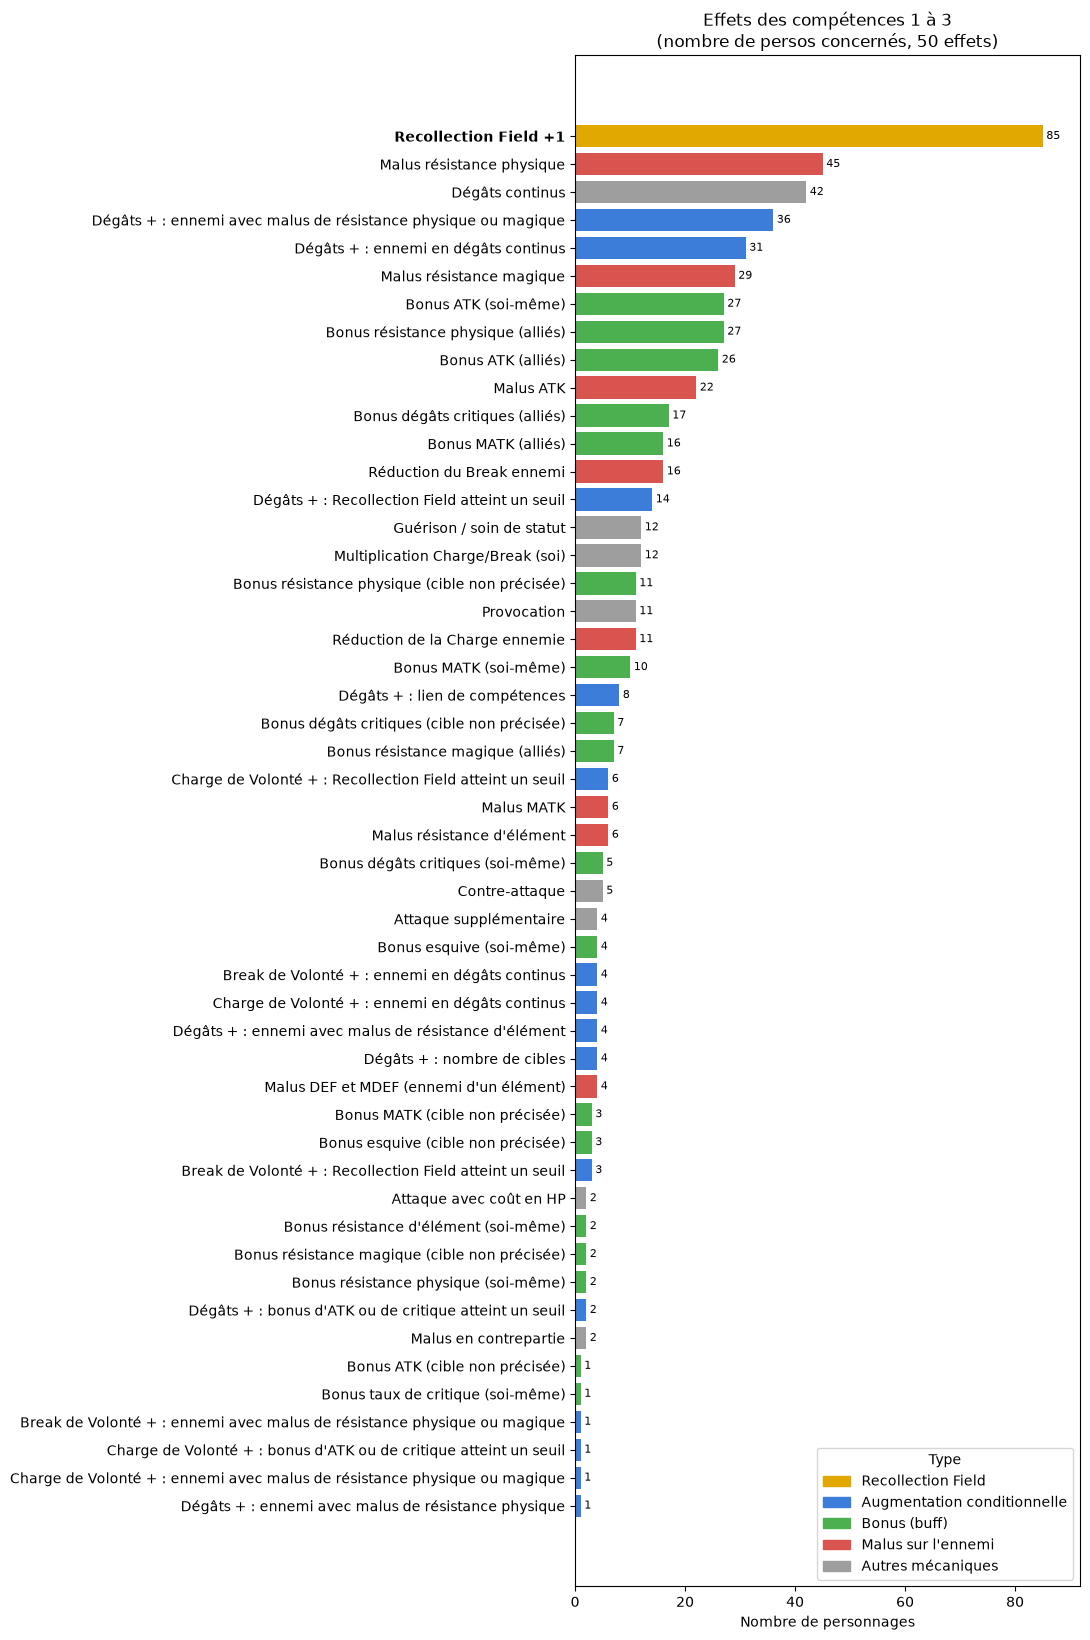

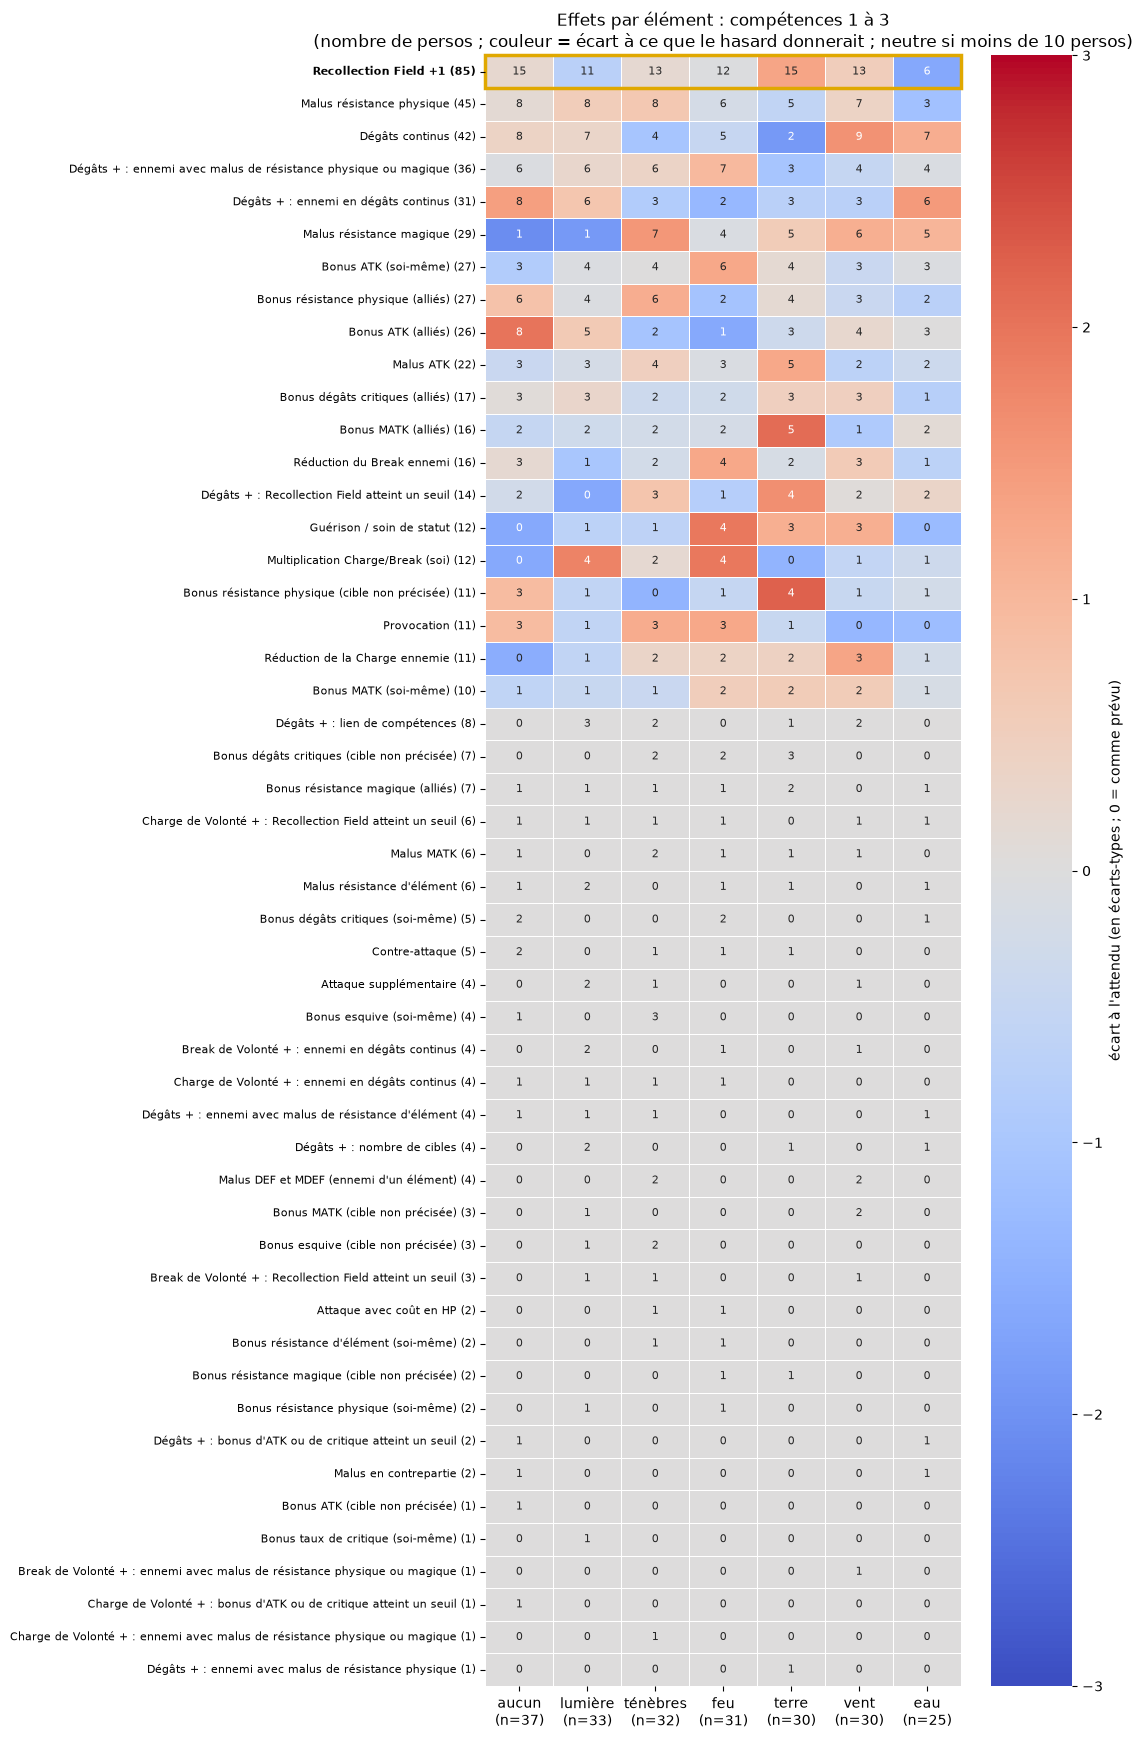

In [32]:
df_eff_sk = construire_effets(SLOTS_COMPETENCES)
table_global_sk = graphique_global(df_eff_sk, "Effets des compétences 1 à 3")
table_element_sk = graphique_par_element(df_eff_sk, "Effets par élément : compétences 1 à 3")

['incarnation'] : 28 effets distincts | phrases non classées (« Autre ») : 0


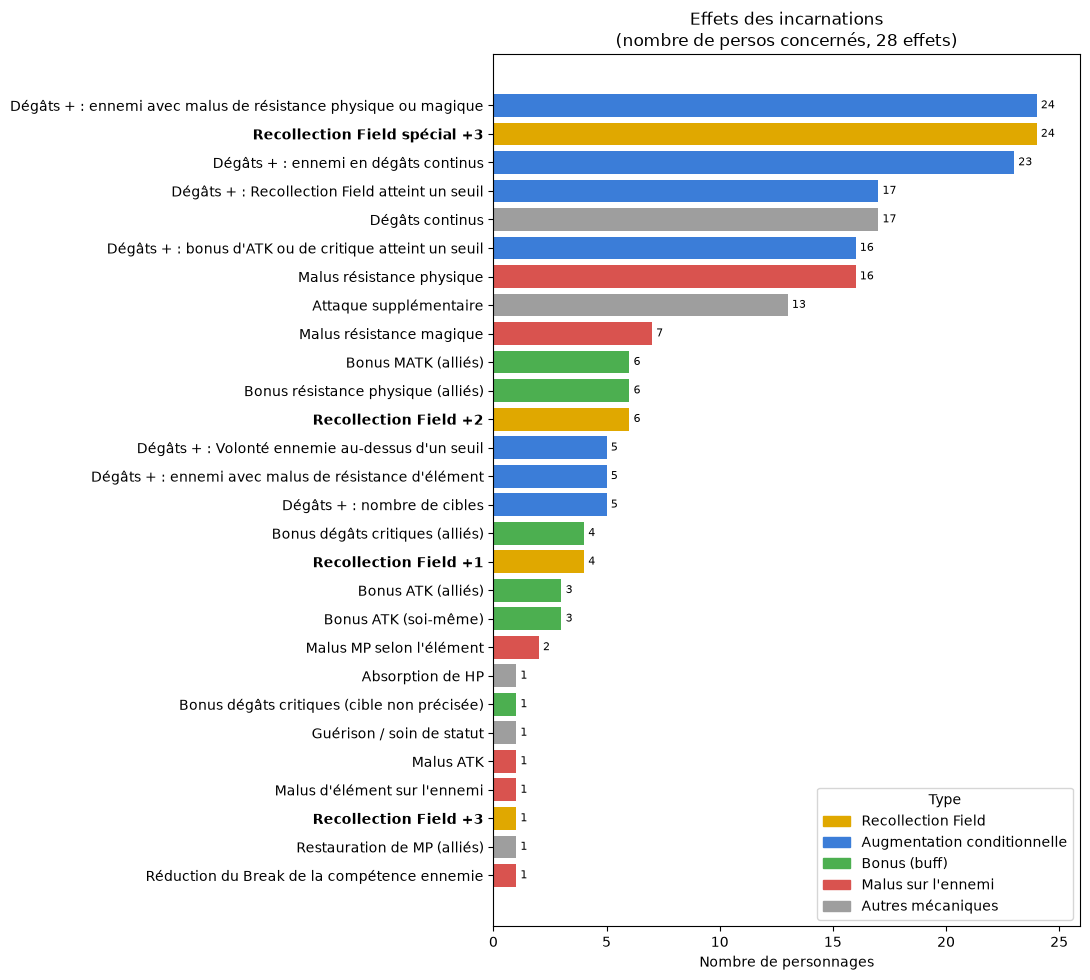

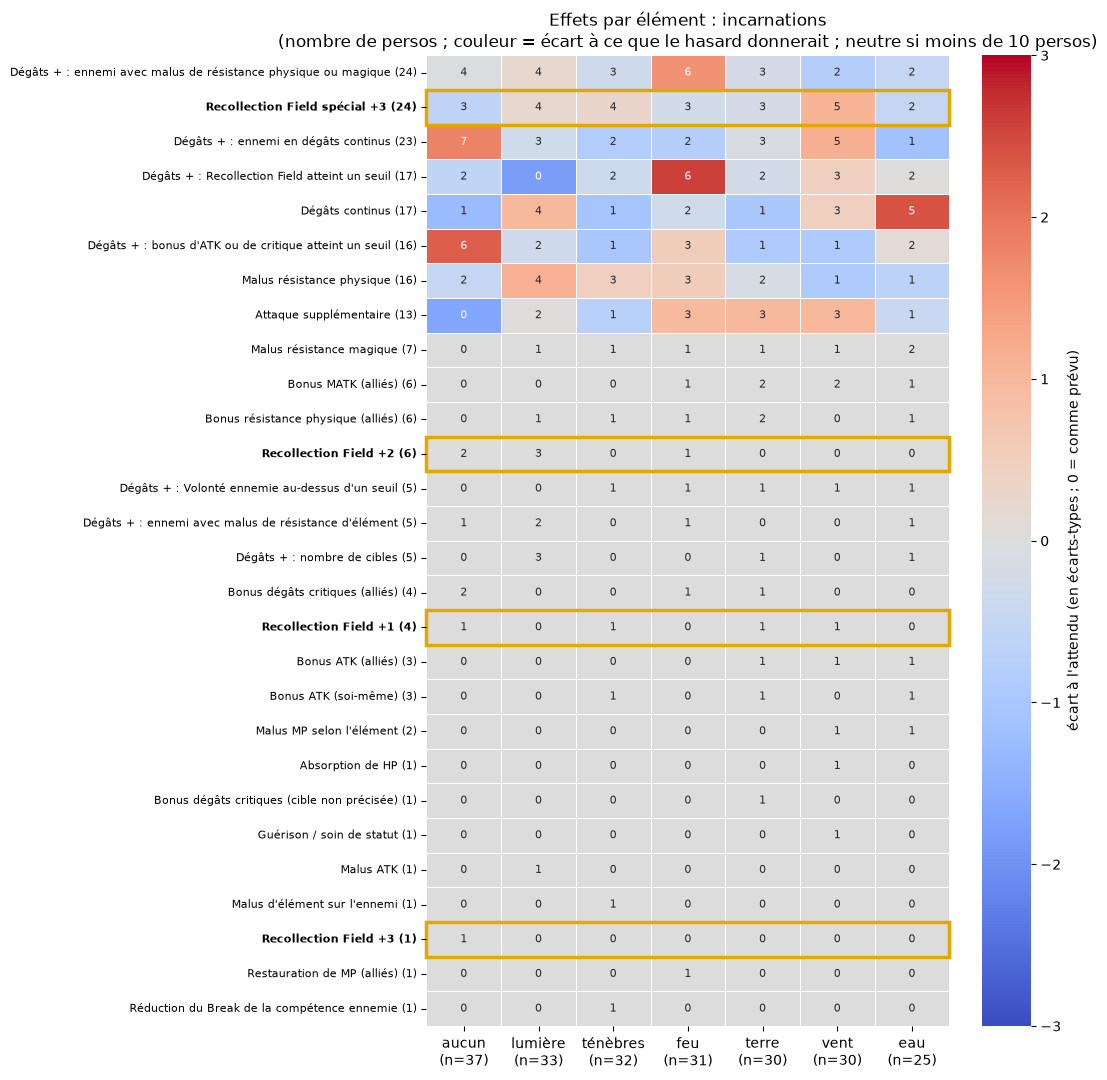

In [33]:
df_eff_inc = construire_effets(SLOTS_INCARNATION)
table_global_inc = graphique_global(df_eff_inc, "Effets des incarnations")
table_element_inc = graphique_par_element(df_eff_inc, "Effets par élément : incarnations")

### Plus de Graph : Comment choisir les stats ?
Graph 1 :
- Le but est de voir quelle stats sont les plus prisée. Il y a aussi une histoire de pas, les stats peuvent avoir des écarts de x pas, donc on peut créer des stats en respectant cette règle
- Néanmoins, comme ce qu iest écrit sur les HP, 61% des perso ont un pas de 15, donc il y a quand même une partie (perso free et non free) qui ne respecte pas la tendance
- Donc la règle peut être appliqué, m'est n'est pas absolue

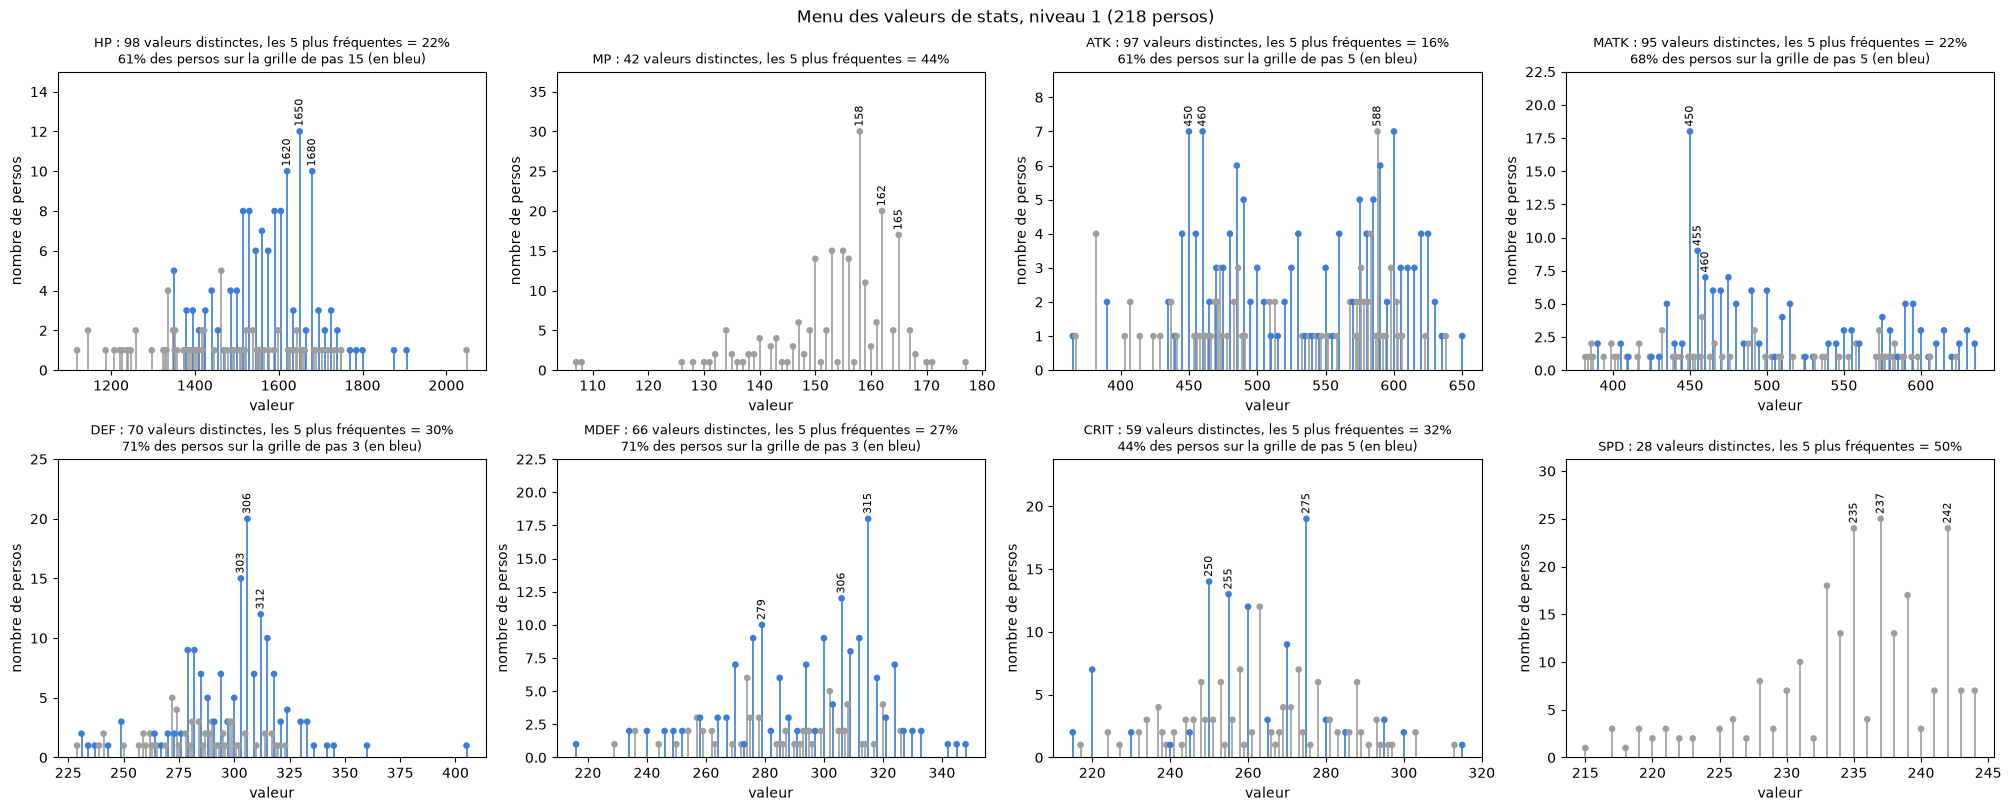

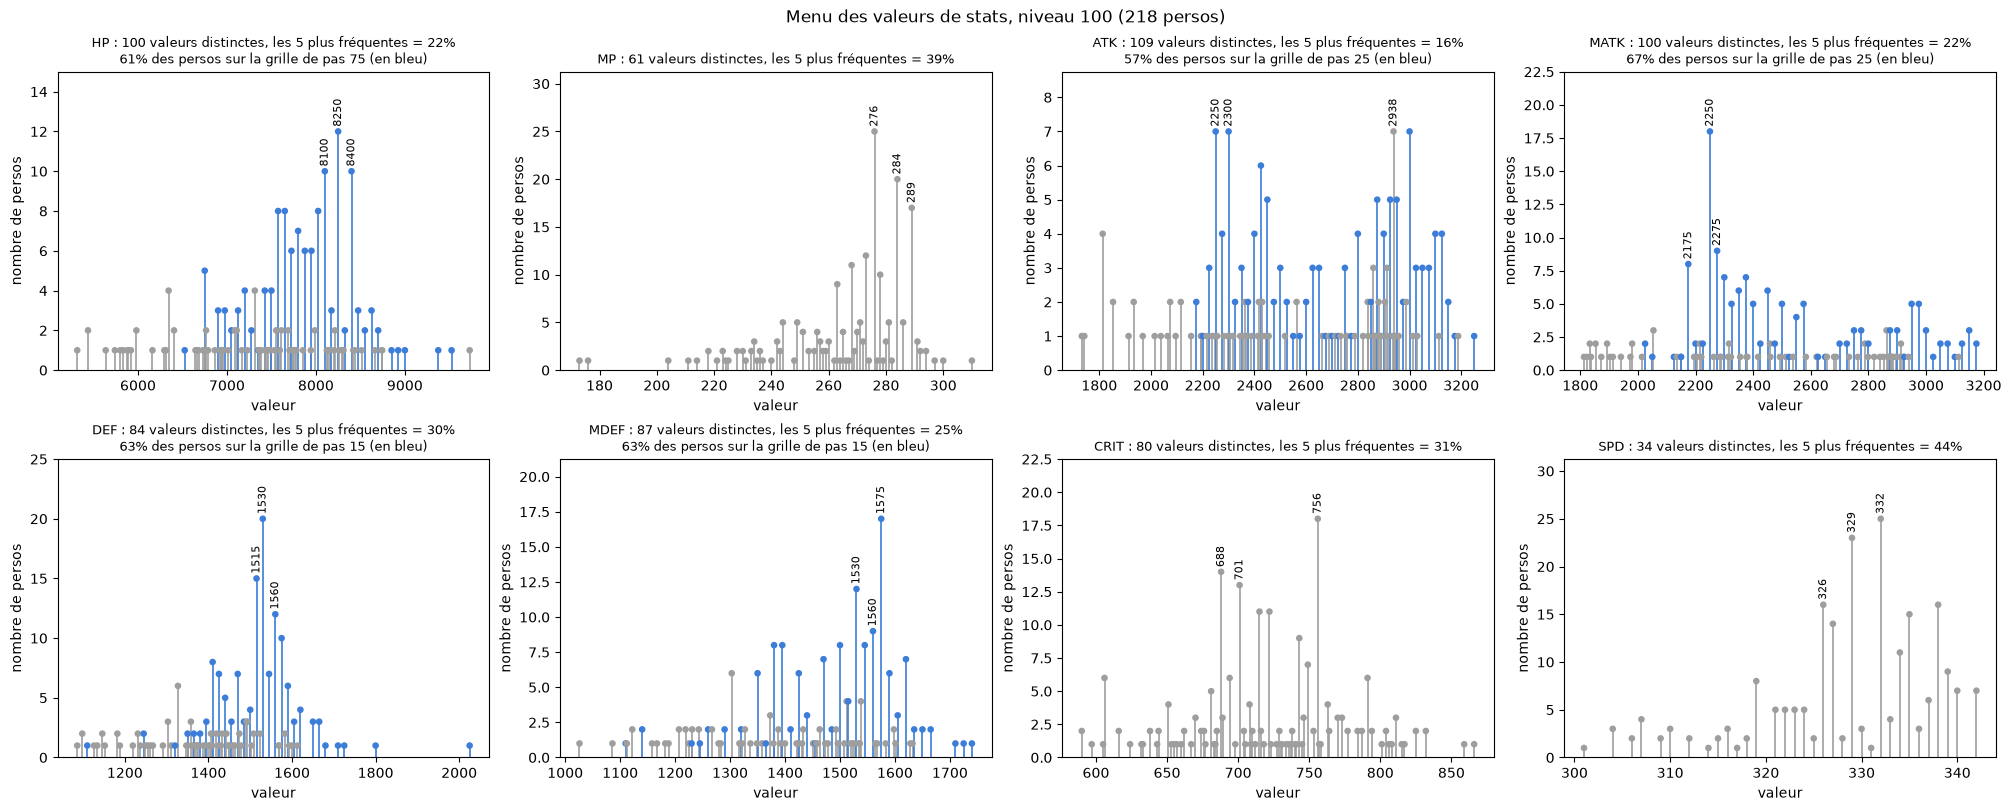

,HP,MP,ATK,MATK,DEF,MDEF,CRIT,SPD
0,7500,276,2700,2550,1455,1395,701,319
1,7875,278,2575,2500,1365,1380,681,318
2,5637,221,2246,1913,1188,1225,723,304
3,7650,269,2650,2450,1485,1395,718,321
4,7725,286,2563,2250,1358,1373,722,330
...,...,...,...,...,...,...,...,...
213,8250,284,3125,2250,1590,1590,756,332
214,8250,236,2900,2050,1650,1230,756,337
215,8100,257,2938,2025,1665,1260,731,337
216,8250,273,3050,2250,1530,1530,688,332


In [34]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def graphique_menu_stats(niveau=1):
    """Pour chaque stat : combien de persos ont EXACTEMENT chaque valeur.
    niveau=1 : les valeurs « sources » (celles du niveau 100 en découlent) ; niveau=100 : valeurs du niveau 100.
    Les points bleus sont les valeurs qui tombent sur la grille repérée pour cette stat."""
    if niveau == 1:
        pas = {"HP": 15, "DEF": 3, "MDEF": 3, "ATK": 5, "MATK": 5, "CRIT": 5}
    elif niveau == 100:
        pas = {"HP": 75, "DEF": 15, "MDEF": 15, "ATK": 25, "MATK": 25}      # le niveau 1 multiplié par 5
    else:
        pas = {}

    pdf = df_perso.select(*[F.col(f"stats.lvl_{niveau}.{s}").alias(s) for s in STATS]).toPandas()

    fig, axes = plt.subplots(2, 4, figsize=(20, 8), layout="constrained")
    for ax, s in zip(axes.ravel(), STATS):
        c = pdf[s].value_counts().sort_index()                       # valeur -> nombre de persos
        sur_grille = (c.index % pas[s] == 0) if s in pas else np.zeros(len(c), dtype=bool)
        couleurs = np.where(sur_grille, "#3b7dd8", "#9e9e9e")
        ax.vlines(c.index, 0, c.values, color=couleurs, linewidth=1.2)
        ax.scatter(c.index, c.values, c=couleurs, s=14, zorder=3)
        for valeur, n in c.nlargest(3).items():                       # les 3 valeurs les plus partagées
            ax.text(valeur, n + c.max() * 0.02, str(valeur), ha="center", va="bottom", rotation=90, fontsize=8)
        top5 = c.nlargest(5).sum() / len(pdf)
        titre = f"{s} : {len(c)} valeurs distinctes, les 5 plus fréquentes = {top5:.0%}"
        if s in pas:
            titre += f"\n{(pdf[s] % pas[s] == 0).mean():.0%} des persos sur la grille de pas {pas[s]} (en bleu)"
        ax.set_title(titre, fontsize=9)
        ax.set_xlabel("valeur"); ax.set_ylabel("nombre de persos")
        ax.set_ylim(0, c.max() * 1.25)
    fig.suptitle(f"Menu des valeurs de stats, niveau {niveau} ({len(pdf)} persos)", fontsize=12)
    plt.show()
    return pdf


pdf_stats = graphique_menu_stats(1)      # niveau 1 : les valeurs de départ
graphique_menu_stats(100)                # même structure, à l'échelle du niveau 100

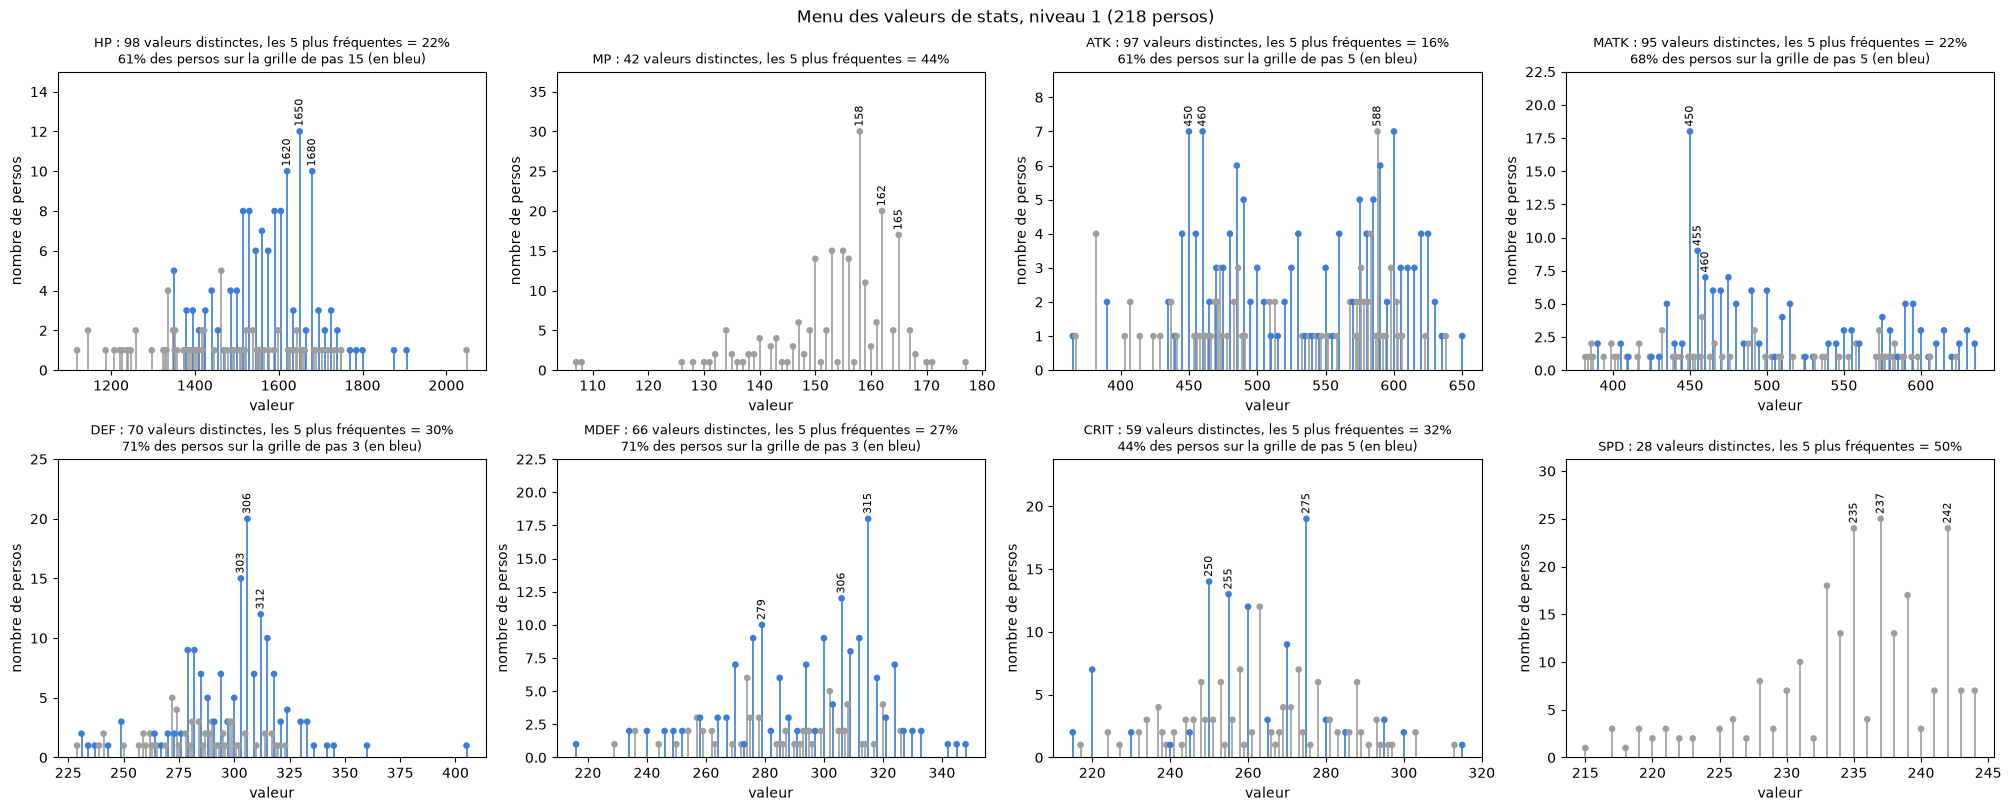

np.float64(0.6146788990825688)

In [35]:
pdf_stats = graphique_menu_stats(1)
(pdf_stats["HP"] % 15 == 0).mean()      # part des persos dont le HP est un multiple de 15

In [36]:
STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def _percentile(serie, v):
    """Part des persos de référence en dessous de v (les égalités comptent pour moitié)."""
    return ((serie < v).sum() + (serie <= v).sum()) / (2 * len(serie)) * 100

def carte_identite(perso=None, stats=None, nom="Perso candidat", niveau=100, famille=None):
    """Carte d'identité d'un perso, par rapport aux persos de la même famille.
    - perso : nom complet d'un perso existant, par exemple "[Magical Stream] Kirito"
    - stats : OU un dictionnaire de stats pour un perso à créer, par exemple {"HP": 8300, "MP": 276, ...}
    - niveau : 1 ou 100 (le niveau des valeurs que tu donnes ou que tu compares)
    La référence est df_perso : elle suit donc ton filtre free."""
    colonnes = [F.col(f"stats.lvl_{niveau}.{s}").alias(s) for s in STATS]
    ref = df_perso.select(*colonnes).toPandas()
    ref["famille"] = np.where(ref["ATK"] > ref["MATK"], "physique",
                              np.where(ref["ATK"] < ref["MATK"], "magique", "indetermine"))

    if perso is not None:                                              # perso existant (même s'il est filtré de df_perso)
        source = df_perso_complet if "df_perso_complet" in globals() else df_perso
        ligne = source.filter(F.col("nom_complet") == perso).select(*colonnes).toPandas()
        if ligne.empty:
            candidats = [r["nom_complet"] for r in source.filter(F.col("nom_complet").contains(perso)).select("nom_complet").limit(8).collect()]
            raise ValueError(f"Perso introuvable : {perso!r}. Candidats proches : {candidats}")
        valeurs = ligne.iloc[0].to_dict(); nom = perso
    else:
        valeurs = {s: stats[s] for s in STATS}

    if famille is None:
        famille = ("physique" if valeurs["ATK"] > valeurs["MATK"]
                   else "magique" if valeurs["ATK"] < valeurs["MATK"] else "indetermine")
    groupe = ref[ref["famille"] == famille] if famille in ("physique", "magique") else ref

    # Percentiles de tous les persos de référence, puis bande 10-90 % de la famille
    pct_ref = pd.DataFrame({s: ref[s].apply(lambda v: _percentile(ref[s], v)) for s in STATS})
    pct_groupe = pct_ref.loc[groupe.index]
    bas, haut, med = pct_groupe.quantile(0.10), pct_groupe.quantile(0.90), pct_groupe.median()
    pct_perso = pd.Series({s: _percentile(ref[s], valeurs[s]) for s in STATS})

    # Calibrage : combien de persos existants de la famille ont autant de stats hors bande ?
    hors_membres = ((pct_groupe < bas) | (pct_groupe > haut)).sum(axis=1)
    hors_perso = int(((pct_perso < bas) | (pct_perso > haut)).sum())
    part_aussi_atypiques = (hors_membres >= hors_perso).mean()

    # Graphique radar
    angles = np.linspace(0, 2 * np.pi, len(STATS), endpoint=False)
    boucle = lambda x: np.concatenate([np.asarray(x), np.asarray(x)[:1]])
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
    ax.fill_between(boucle(angles), boucle(bas), boucle(haut), color="#3b7dd8", alpha=0.25, linewidth=0,
                    label=f"10 à 90 % des persos {famille}s (n={len(groupe)})")
    ax.plot(boucle(angles), boucle(med), color="#3b7dd8", linestyle="--", linewidth=1, label="médiane de la famille")
    ax.plot(boucle(angles), boucle(pct_perso), "o-", color="#d9534f", linewidth=2, label=nom)
    ax.set_xticks(angles); ax.set_xticklabels(STATS)
    ax.set_ylim(0, 100); ax.set_yticks([25, 50, 75, 100]); ax.set_yticklabels(["25", "50", "75", "100"], fontsize=8)
    ax.set_title(f"Carte d'identité (niveau {niveau}, référence : {len(ref)} persos)", pad=18)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=8)
    plt.tight_layout()
    plt.show()

    # Tableau et verdict
    verdict = ["au-dessus de la bande" if pct_perso[s] > haut[s] else "en dessous de la bande" if pct_perso[s] < bas[s]
               else "dans la bande" for s in STATS]
    tableau = pd.DataFrame({"stat": STATS, "valeur": [valeurs[s] for s in STATS],
                            "percentile": pct_perso.round(0).astype(int).values,
                            "bande 10-90": [f"{bas[s]:.0f} à {haut[s]:.0f}" for s in STATS], "verdict": verdict})
    print(tableau.to_string(index=False))
    print(f"\n{hors_perso} stat(s) hors bande sur 8. Parmi les persos {famille}s de la référence, "
          f"{part_aussi_atypiques:.0%} en ont au moins autant.")
    return tableau

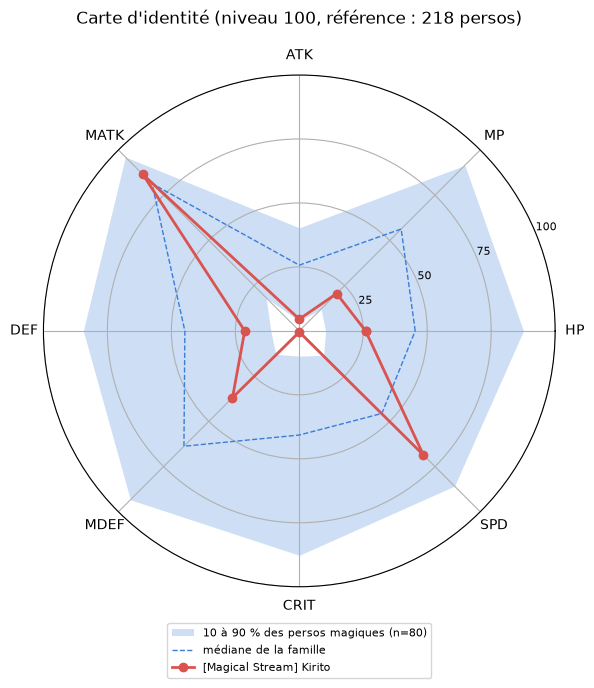

stat  valeur  percentile bande 10-90                verdict
  HP    7166          26     10 à 88          dans la bande
  MP     251          21     12 à 92          dans la bande
 ATK    1933           5      4 à 40          dans la bande
MATK    2920          86     18 à 96          dans la bande
 DEF    1375          21     11 à 84          dans la bande
MDEF    1424          37     13 à 93          dans la bande
CRIT     590           0     10 à 88 en dessous de la bande
 SPD     334          69     13 à 86          dans la bande

1 stat(s) hors bande sur 8. Parmi les persos magiques de la référence, 70% en ont au moins autant.


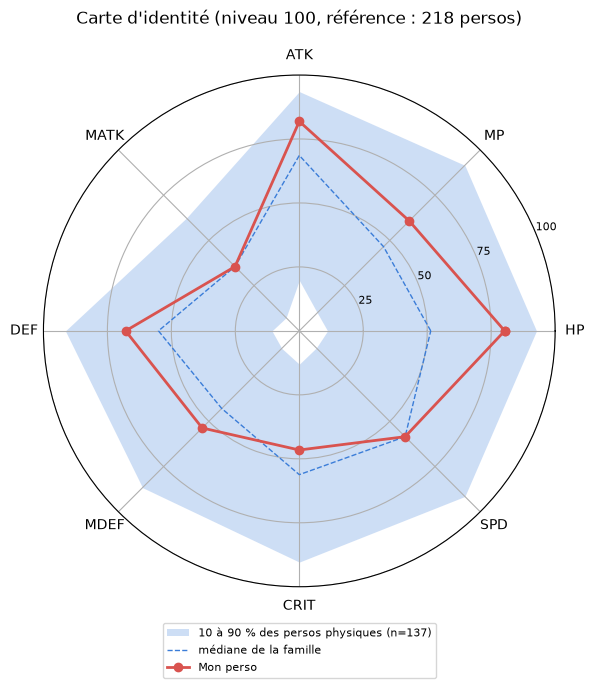

stat  valeur  percentile bande 10-90       verdict
  HP    8250          80     11 à 93 dans la bande
  MP     276          61     10 à 92 dans la bande
 ATK    2950          82     20 à 94 dans la bande
MATK    2300          36      7 à 62 dans la bande
 DEF    1530          68     11 à 91 dans la bande
MDEF    1500          54     10 à 87 dans la bande
CRIT     715          47     13 à 90 dans la bande
 SPD     332          58      9 à 92 dans la bande

0 stat(s) hors bande sur 8. Parmi les persos physiques de la référence, 100% en ont au moins autant.


,stat,valeur,percentile,bande 10-90,verdict
0,HP,8250,80,11 à 93,dans la bande
1,MP,276,61,10 à 92,dans la bande
2,ATK,2950,82,20 à 94,dans la bande
3,MATK,2300,36,7 à 62,dans la bande
4,DEF,1530,68,11 à 91,dans la bande
5,MDEF,1500,54,10 à 87,dans la bande
6,CRIT,715,47,13 à 90,dans la bande
7,SPD,332,58,9 à 92,dans la bande


In [37]:
# Un perso existant (même un free, même si le filtre l'a retiré de df_perso)
carte_identite(perso="[Magical Stream] Kirito")

# Un perso à créer (valeurs du niveau 100)
carte_identite(stats={"HP": 8250, "MP": 276, "ATK": 2950, "MATK": 2300,
                      "DEF": 1530, "MDEF": 1500, "CRIT": 715, "SPD": 332},
               nom="Mon perso")



['competence_1', 'competence_2', 'competence_3'] : 50 effets distincts | phrases non classées (« Autre ») : 0


C:\Users\theot\AppData\Local\Temp\ipykernel_17264\274068101.py:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .pivot(index="perso_id", columns="effet", values="v").reindex(base.index).fillna(False).astype(bool))


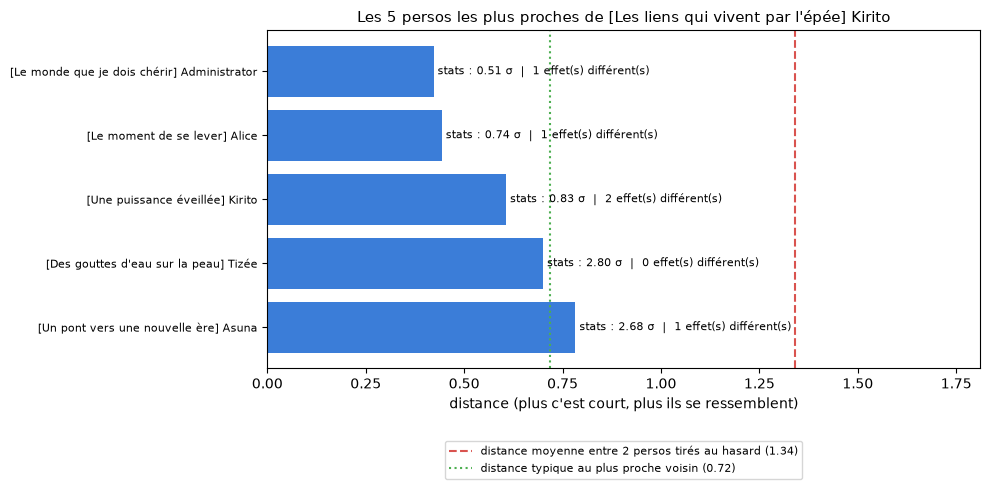

                                     voisin  écart stats (écarts-types)  effets différents                                                                             en commun
[Le monde que je dois chérir] Administrator                    0.508588                  1 Rôle Charge, Rôle Mode enhance, Dégâts + : ennemi en dégâts continus, Dégâts continus
              [Le moment de se lever] Alice                    0.739734                  1 Rôle Charge, Rôle Mode enhance, Dégâts + : ennemi en dégâts continus, Dégâts continus
            [Une puissance éveillée] Kirito                    0.832520                  2                    Rôle Charge, Dégâts + : ennemi en dégâts continus, Dégâts continus
      [Des gouttes d'eau sur la peau] Tizée                    2.802830                  0 Rôle Charge, Rôle Mode enhance, Dégâts + : ennemi en dégâts continus, Dégâts continus
      [Un pont vers une nouvelle ère] Asuna                    2.684205                  1                    Rôle 

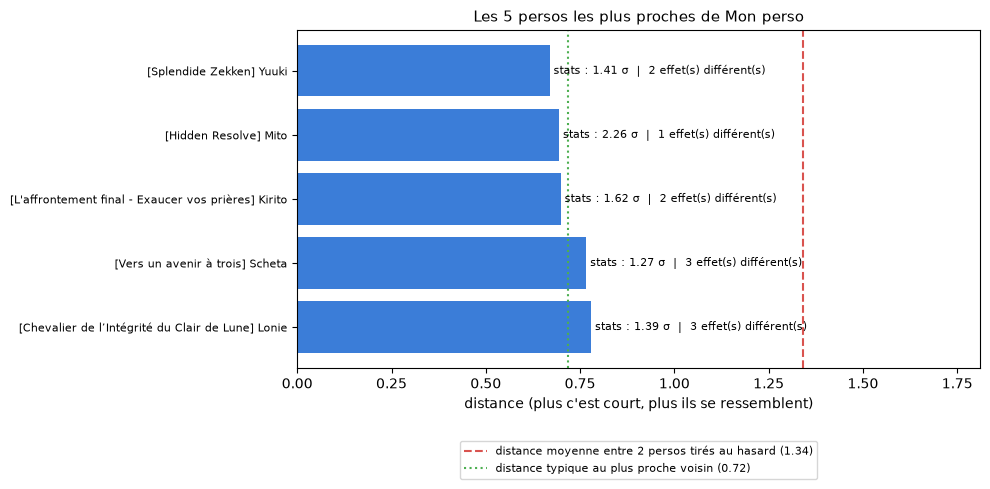

                                             voisin  écart stats (écarts-types)  effets différents                                                 en commun
                           [Splendide Zekken] Yuuki                    1.407259                  2                            Rôle Charge, Rôle Mode enhance
                              [Hidden Resolve] Mito                    2.263599                  1                            Rôle Charge, Rôle Mode enhance
[L'affrontement final - Exaucer vos prières] Kirito                    1.619932                  2 Rôle Charge, Rôle Mode enhance, Malus résistance physique
                    [Vers un avenir à trois] Scheta                    1.270730                  3              Rôle Mode enhance, Malus résistance physique
  [Chevalier de l’Intégrité du Clair de Lune] Lonie                    1.390379                  3 Rôle Charge, Rôle Mode enhance, Malus résistance physique


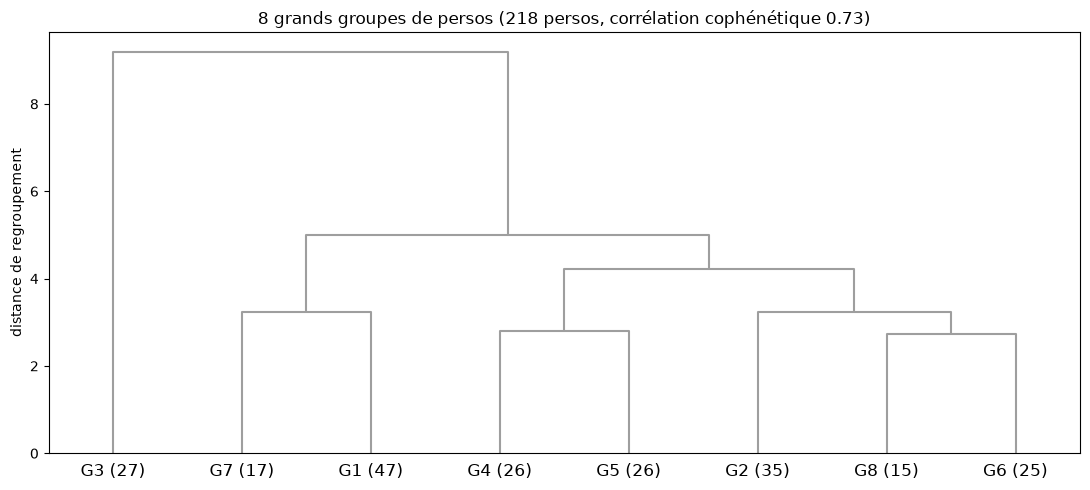

groupe  n % physiques % Break % Charge % Mode enh. % free   HP   MP  ATK MATK  DEF MDEF CRIT  SPD
    G1 47         13%     38%      45%         49%     0% +0.3 +0.5 -0.6 +1.3 +0.4 +0.7 -0.0 +0.5
    G2 35         63%      6%      80%          9%     0% -0.5 +0.4 +0.0 +0.2 -0.2 -0.1 +0.7 -0.4
    G3 27         59%     63%      37%          7%   100% -1.8 -1.8 -1.6 -1.4 -1.8 -1.8 -1.2 -1.4
    G4 26        100%     62%      50%         19%     4% +0.9 +0.3 +1.1 -0.5 +0.9 +0.8 +0.3 +0.6
    G5 26        100%     62%      42%         92%     0% +0.6 +0.8 +0.9 -0.5 +0.5 +0.4 +0.2 -0.0
    G6 25         92%     36%      64%         12%     4% +0.2 -0.3 +0.5 -0.4 +0.2 -0.5 +0.4 +0.5
    G7 17         29%     65%      29%         18%    47% +0.3 -0.6 -0.4 +0.5 -0.4 -0.2 -1.0 -0.3
    G8 15         87%     67%      47%          0%     0% -0.0 -0.1 +0.6 -0.2 +0.2 +0.2 +0.3 +0.5

(Les colonnes de stats donnent l'écart moyen du groupe à la moyenne générale, en écarts-types.)


perso_id
130114006           [Torrent de techniques] Kirito
130114007                [Le chevalier ailé] Renly
130114009              [Vent du champ glacé] Eugeo
130114014                   [Un autre héros] Eugeo
130124018                [L'éclat du sabre] Suguha
130124032        [Le chevalier inébranlable] Alice
130134006                [Le lancier vert] Nergius
130324008     [Courant lumineux de guérison] Asuna
130324015          [La belle étoile filante] Asuna
130324027            [Un matin sur le front] Asuna
130324035    [Un pont vers une nouvelle ère] Asuna
130344009            [Atteindre cette force] Tizée
130454010        [Détente au bord de l'eau] Silica
130624002             [Je veux donc je peux] Sinon
131214003              [Un meneur d'avenir] Iskahn
Name: nom_complet, dtype: object

In [38]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram, to_tree

STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def construire_espace(df_eff, poids_stats=0.5, niveau=100):
    """Représente chaque perso par ses stats (centrées-réduites) et son « kit » (rôles + effets, 0/1).
    poids_stats = 0.5 : stats et kit pèsent autant ; 1 = stats seules ; 0 = kit seul.
    La référence est df_perso : elle suit ton filtre free."""
    cols = [F.col(f"stats.lvl_{niveau}.{s}").alias(s) for s in STATS]
    libre = F.col("free") if "free" in df_perso.columns else F.lit(False)
    base = (df_perso.select(F.col("id").alias("perso_id"), "nom_complet", "element", "arme", libre.alias("free"),
                            F.col("competences.competence_1.categorie").alias("c1"),
                            F.col("competences.competence_2.categorie").alias("c2"),
                            F.col("competences.competence_3.categorie").alias("c3"), *cols)
            .toPandas().set_index("perso_id"))
    cats = base[["c1", "c2", "c3"]].fillna("")
    roles = pd.DataFrame({
        "Rôle Break": cats.apply(lambda r: any("BREAK" in x for x in r), axis=1),
        "Rôle Charge": cats.apply(lambda r: any("CHARGE" in x for x in r), axis=1),
        "Rôle Mode enhance": cats.apply(lambda r: any(x == "ENHANCE_MODE" for x in r), axis=1)})
    effets = (df_eff.select("perso_id", "effet").distinct().toPandas().assign(v=True)
              .pivot(index="perso_id", columns="effet", values="v").reindex(base.index).fillna(False).astype(bool))
    kit = pd.concat([roles, effets], axis=1)
    kit = kit.loc[:, kit.std(ddof=0) > 0].astype(float)                  # on garde les éléments qui varient

    moy, std = base[STATS].mean(), base[STATS].std(ddof=0)
    Z = (base[STATS] - moy) / std
    moy_k = kit.mean(); ech_k = np.sqrt(((kit - moy_k) ** 2).mean().sum())
    X = np.hstack([np.sqrt(poids_stats) * Z.values / np.sqrt(len(STATS)),
                   np.sqrt(1 - poids_stats) * ((kit - moy_k) / ech_k).values])
    D = squareform(pdist(X))
    iu = np.triu_indices(len(X), 1)
    plus_proche = (D + np.eye(len(X)) * 1e9).min(axis=1)
    return dict(base=base, Z=Z, kit=kit, roles=roles, X=X, D=D, w=poids_stats, moy=moy, std=std, moy_k=moy_k, ech_k=ech_k,
                med_paires=np.median(D[iu]), med_nn=np.median(plus_proche), niveau=niveau)

def voisins(esp, perso=None, stats=None, kit=(), k=5, nom="Perso candidat"):
    """Les k persos les plus proches d'un perso existant (perso=...) ou d'un perso à créer (stats=..., kit=[...])."""
    base, kit_df = esp["base"], esp["kit"]
    if perso is not None:
        pos = np.flatnonzero(base["nom_complet"].values == perso)
        if len(pos) == 0:
            proches = base.index[base["nom_complet"].str.contains(perso, regex=False)]
            raise ValueError(f"Perso introuvable dans la référence : {perso!r}. Proches : {base.loc[proches, 'nom_complet'].head(8).tolist()}"
                             " (si c'est un free, vérifie ton filtre free)")
        i = pos[0]; x = esp["X"][i]; z = esp["Z"].values[i]; v = kit_df.values[i]; nom = perso
    else:
        z = ((pd.Series(stats)[STATS] - esp["moy"]) / esp["std"]).values
        v = np.array([1.0 if c in kit else 0.0 for c in kit_df.columns]); i = None
        inconnus = [c for c in kit if c not in kit_df.columns]
        if inconnus: print("Éléments de kit ignorés (inconnus ou constants) :", inconnus)
        x = np.hstack([np.sqrt(esp["w"]) * z / np.sqrt(len(STATS)),
                       np.sqrt(1 - esp["w"]) * ((v - esp["moy_k"].values) / esp["ech_k"])])
    dist = np.linalg.norm(esp["X"] - x, axis=1)
    if i is not None: dist[i] = np.inf
    ordre = np.argsort(dist)[:k]
    lignes = []
    for j in ordre:
        communs = [c for c in kit_df.columns if kit_df.values[j, list(kit_df.columns).index(c)] == 1 and v[list(kit_df.columns).index(c)] == 1]
        lignes.append({"voisin": base["nom_complet"].iloc[j], "distance": dist[j],
                       "écart stats (écarts-types)": np.linalg.norm(esp["Z"].values[j] - z),
                       "effets différents": int((kit_df.values[j] != v).sum()),
                       "en commun": ", ".join(communs[:4]) + (" …" if len(communs) > 4 else "")})
    t = pd.DataFrame(lignes)

    fig, ax = plt.subplots(figsize=(10, 3.6 + 0.3 * k))
    y = np.arange(k)[::-1]
    ax.barh(y, t["distance"], color="#3b7dd8")
    for yy, (_, r) in zip(y, t.iterrows()):
        ax.text(r["distance"] + 0.01, yy, f"stats : {r['écart stats (écarts-types)']:.2f} σ  |  {r['effets différents']} effet(s) différent(s)", va="center", fontsize=8)
    ax.axvline(esp["med_paires"], color="#d9534f", linestyle="--", label=f"distance moyenne entre 2 persos tirés au hasard ({esp['med_paires']:.2f})")
    ax.axvline(esp["med_nn"], color="#4caf50", linestyle=":", label=f"distance typique au plus proche voisin ({esp['med_nn']:.2f})")
    ax.set_yticks(y); ax.set_yticklabels(t["voisin"], fontsize=8)
    ax.set_xlim(0, esp["med_paires"] * 1.35)
    ax.set_xlabel("distance (plus c'est court, plus ils se ressemblent)")
    ax.set_title(f"Les {k} persos les plus proches de {nom}", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
    plt.tight_layout(); plt.show()
    print(t.drop(columns="distance").to_string(index=False))
    return t

def dendrogramme(esp, n_groupes=8):
    """Arbre de regroupement (méthode de Ward) tronqué à n_groupes groupes, et description de chaque groupe."""
    L = linkage(esp["X"], "ward")
    cophenetique = cophenet(L, pdist(esp["X"]))[0]
    etiquettes = fcluster(L, n_groupes, "maxclust")
    tailles = pd.Series(etiquettes).value_counts()
    nom_groupe = {g: f"G{r + 1}" for r, g in enumerate(tailles.index)}            # G1 = le plus gros groupe
    _, noeuds = to_tree(L, rd=True)
    def etiquette(i):
        membres = noeuds[i].pre_order()
        return f"{nom_groupe[etiquettes[membres[0]]]} ({len(membres)})"
    hauteur = (L[-(n_groupes - 1), 2] + L[-n_groupes, 2]) / 2

    fig, ax = plt.subplots(figsize=(11, 5))
    dendrogram(L, truncate_mode="lastp", p=n_groupes, leaf_label_func=etiquette, color_threshold=hauteur,
               above_threshold_color="#9e9e9e", ax=ax)
    ax.set_ylabel("distance de regroupement")
    ax.set_title(f"{n_groupes} grands groupes de persos ({len(esp['X'])} persos, corrélation cophénétique {cophenetique:.2f})")
    plt.tight_layout(); plt.show()

    base, Z, roles = esp["base"], esp["Z"], esp["roles"]
    g = pd.Series([nom_groupe[e] for e in etiquettes], index=base.index)
    lignes = []
    for nom in sorted(nom_groupe.values(), key=lambda s: int(s[1:])):
        m = (g == nom).values
        ligne = {"groupe": nom, "n": int(m.sum()),
                 "% physiques": f"{(base.loc[m, 'ATK'] > base.loc[m, 'MATK']).mean():.0%}",
                 "% Break": f"{roles.loc[m, 'Rôle Break'].mean():.0%}", "% Charge": f"{roles.loc[m, 'Rôle Charge'].mean():.0%}",
                 "% Mode enh.": f"{roles.loc[m, 'Rôle Mode enhance'].mean():.0%}", "% free": f"{base.loc[m, 'free'].mean():.0%}"}
        ligne.update({s: f"{Z.loc[m, s].mean():+.1f}" for s in STATS})
        lignes.append(ligne)
    t = pd.DataFrame(lignes)
    print(t.to_string(index=False))
    print("\n(Les colonnes de stats donnent l'écart moyen du groupe à la moyenne générale, en écarts-types.)")
    return g, t



df_sk = construire_effets(SLOTS_COMPETENCES)     # effets des compétences 1 à 3
esp = construire_espace(df_sk)                   # prépare les distances (stats et kit pèsent autant)

# 1) Les voisins d'un perso existant
voisins(esp, perso="[Les liens qui vivent par l'épée] Kirito")

# 2) Les voisins d'un perso à créer (les noms du kit sont dans esp["kit"].columns)
voisins(esp,
        stats={"HP": 8250, "MP": 276, "ATK": 2950, "MATK": 2300, "DEF": 1530, "MDEF": 1500, "CRIT": 715, "SPD": 332},
        kit=["Rôle Charge", "Rôle Mode enhance", "Malus résistance physique"],
        nom="Mon perso")

# 3) L'arbre, et la liste des persos d'un groupe
g, tableau = dendrogramme(esp, n_groupes=8)
esp["base"].loc[g == "G8", "nom_complet"]

In [42]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None

STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def preparer_acp(pdf):
    """pdf : DataFrame pandas avec nom_complet, element, arme, free + les 8 stats."""
    pdf = pdf.reset_index(drop=True).copy()
    pdf["famille"] = np.where(pdf["ATK"] >= pdf["MATK"], "physique", "magique")
    X = pdf[STATS].astype(float)
    moy, std = X.mean(), X.std(ddof=0)
    Z = (X - moy) / std
    U, S, Vt = np.linalg.svd(Z.values, full_matrices=False)
    var = S**2 / (S**2).sum()
    scores = pd.DataFrame(U * S, columns=[f"PC{i+1}" for i in range(len(S))])
    load = pd.DataFrame(Vt.T, index=STATS, columns=scores.columns)
    for c in scores.columns:                       # PC positif = stats plutôt hautes
        if load[c].sum() < 0:
            scores[c] *= -1; load[c] *= -1
    return dict(pdf=pdf, Z=Z, moy=moy, std=std, Vt=Vt, S=S, var=var, scores=scores, load=load)

def eta2(scores, cat):
    """Part de la variance d'un axe expliquée par une catégorie (0 à 1)."""
    out = {}
    for c in ["PC1", "PC2"]:
        g = scores[c].groupby(cat.values)
        out[c] = ((g.mean() - scores[c].mean())**2 * g.size()).sum() / ((scores[c] - scores[c].mean())**2).sum()
    return out

def projeter(acp, stats):
    z = (pd.Series(stats)[STATS].astype(float) - acp["moy"]) / acp["std"]
    sign = np.sign(acp["Vt"].T[:, :2].sum(axis=0)); sign[sign == 0] = 1
    return (z.values @ acp["Vt"].T[:, :2]) * sign

def carte_2d(acp, couleur="famille", stats_candidat=None, nom_candidat="Candidat",
             n_noms=8, fleches=True):
    pdf, sc, var, load = acp["pdf"], acp["scores"], acp["var"], acp["load"]
    fig, ax = plt.subplots(figsize=(11, 8))
    cats = pdf[couleur].astype(str)
    cmap = plt.get_cmap("tab10")
    for i, c in enumerate(sorted(cats.unique())):
        m = (cats == c).values
        ax.scatter(sc.PC1[m], sc.PC2[m], s=38, alpha=.75, color=cmap(i),
                   label=f"{c} ({m.sum()})", edgecolor="white", linewidth=.4)
    if fleches:
        k = 0.7 * np.abs(sc[["PC1", "PC2"]].values).max() / np.abs(load[["PC1", "PC2"]].values).max()
        ax.scatter(load.PC1 * k * 1.15, load.PC2 * k * 1.15, alpha=0)   # agrandit les limites
        for s in STATS:
            x, y = load.loc[s, "PC1"] * k, load.loc[s, "PC2"] * k
            ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#444", lw=1))
            ax.text(x * 1.07, y * 1.07, s, fontsize=10, weight="bold", color="#222", ha="center", va="center")
    d = np.hypot(sc.PC1, sc.PC2).sort_values(ascending=False).index[:n_noms]   # les plus excentriques
    txt = [ax.text(sc.PC1[i], sc.PC2[i], pdf.nom_complet[i], fontsize=7.5) for i in d]
    if stats_candidat is not None:
        x, y = projeter(acp, stats_candidat)
        ax.scatter([x], [y], marker="*", s=420, color="gold", edgecolor="black", zorder=5, label=nom_candidat)
        txt.append(ax.text(x, y, " " + nom_candidat, weight="bold"))
    if adjust_text: adjust_text(txt, ax=ax)
    def axe(p):
        top = load[p].abs().sort_values(ascending=False).index[:3]
        return f"{p} — {var[int(p[2:])-1]:.0%} de la variance\n(" + ", ".join(
            f"{s} {'+' if load.loc[s,p]>0 else '−'}" for s in top) + ")"
    ax.set_xlabel(axe("PC1")); ax.set_ylabel(axe("PC2"))
    ax.axhline(0, color="#bbb", lw=.6); ax.axvline(0, color="#bbb", lw=.6)
    ax.set_title(f"Carte 2D des personnages (stats niv.100), couleur = {couleur}\n"
                 f"PC1+PC2 = {var[:2].sum():.0%} de l'information")
    ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

def resume_acp(acp):
    print("Variance expliquée :", " | ".join(f"PC{i+1} {v:.0%}" for i, v in enumerate(acp["var"][:4])),
          f"| cumul 2 axes {acp['var'][:2].sum():.0%}")
    print("\nPoids (loadings) :"); print(acp["load"][["PC1", "PC2", "PC3"]].round(2))
    print("\nPart de l'axe expliquée par la catégorie (eta², 0-1) :")
    for c in ["famille", "element", "arme", "free"]:
        if c in acp["pdf"]:
            e = eta2(acp["scores"], acp["pdf"][c].astype(str))
            print(f"  {c:8s} PC1 {e['PC1']:.2f}  PC2 {e['PC2']:.2f}")

(218, 12)
Variance expliquée : PC1 28% | PC2 23% | PC3 14% | PC4 12% | cumul 2 axes 51%

Poids (loadings) :
       PC1   PC2   PC3
HP    0.49  0.31 -0.26
MP   -0.17  0.25  0.22
ATK   0.49 -0.35  0.10
MATK -0.39  0.53  0.06
DEF   0.49  0.27 -0.03
MDEF  0.19  0.50  0.38
CRIT -0.01 -0.29  0.77
SPD   0.24  0.19  0.37

Part de l'axe expliquée par la catégorie (eta², 0-1) :
  famille  PC1 0.35  PC2 0.40
  element  PC1 0.04  PC2 0.03
  arme     PC1 0.09  PC2 0.07
  free     PC1 0.00  PC2 0.00


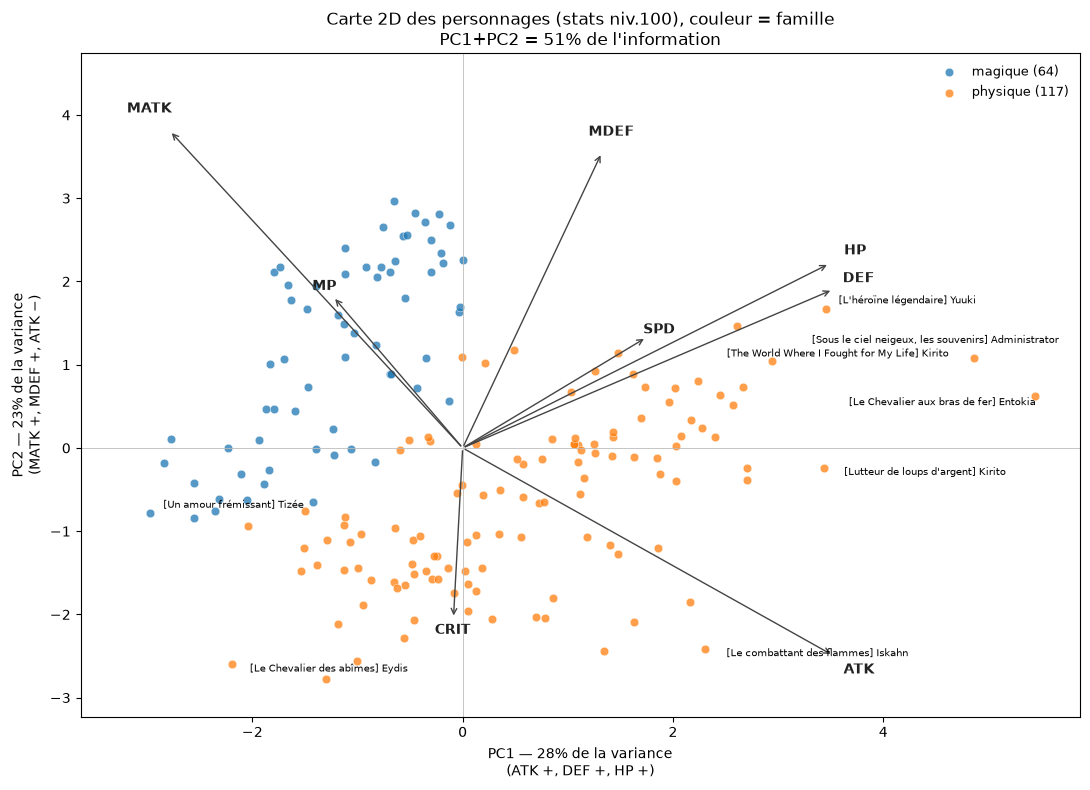

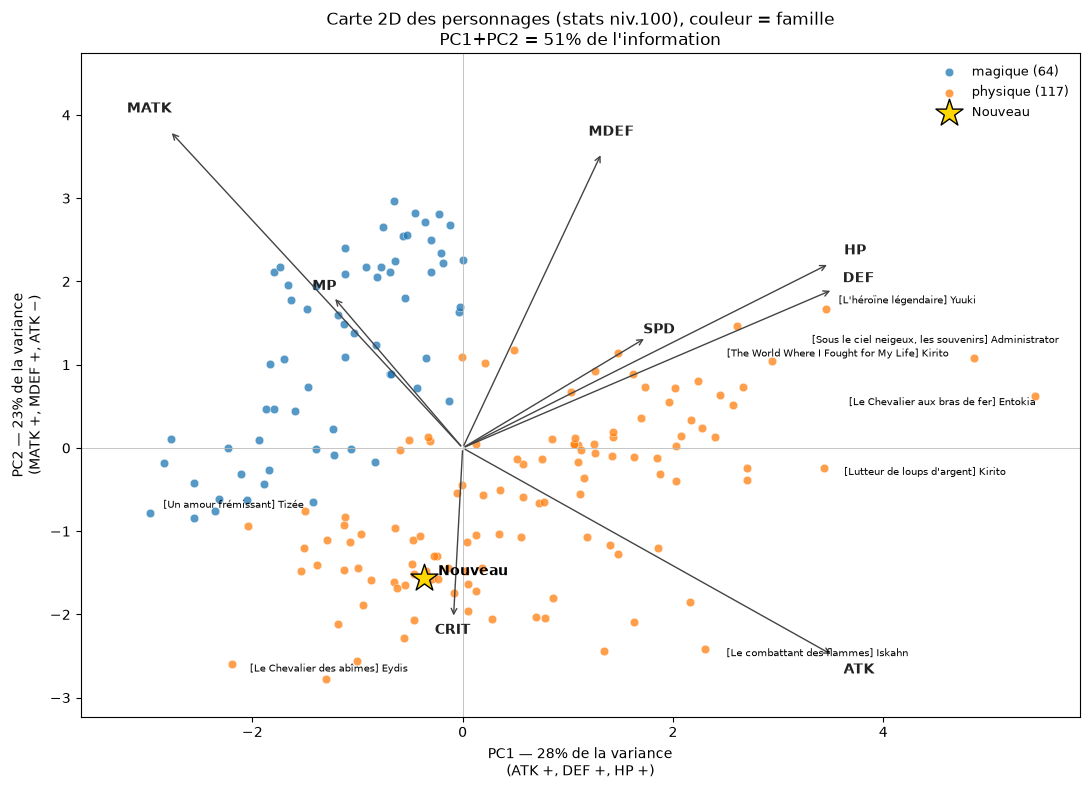

In [46]:
pdf = (df_perso_complet
       .select("nom_complet", "element", "arme", "free",
               *[F.col(f"stats.lvl_100.{s}").alias(s) for s in STATS])
       .toPandas())

print(pdf.shape)          # attendu : (218, 12)
pdf.head(3)

# SANS les free (commente la ligne pour les inclure)
acp = preparer_acp(pdf[~pdf["free"]])
# acp = preparer_acp(pdf)

resume_acp(acp)
carte_2d(acp, couleur="famille")      # essaie aussi "element", "arme", "free"

# Tester un candidat :
carte_2d(acp, couleur="famille", nom_candidat="Nouveau",
         stats_candidat=dict(HP=7500, MP=280, ATK=2900, MATK=2200,
                             DEF=1450, MDEF=1400, CRIT=700, SPD=320))

In [47]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# niveau de chaque compétence selon le niveau du perso (lvl 100 -> 3/3/2/3 ; lvl 120 -> max)
NIVEAUX_100 = {"competence_1": 3, "competence_2": 3, "competence_3": 2, "incarnation": 3}

# Pour chaque "état" de l'ennemi : comment on le FOURNIT (offre) et comment on en PROFITE (demande)
ETATS = {
    "Dégâts continus": dict(
        offre=r"Inflige des dégâts continus",
        demande=r"subissant (des )?dégâts continus"),
    "Malus de résistance phys./mag.": dict(
        offre=r"[Rr]ésistances? (physique|magique)(?![^,.()]*soi-même)[^,.()]*-[0-9]+ ?%",
        demande=r"subissant un malus de résistance physique"),
    "Malus de résistance d'élément": dict(
        offre=r"[Rr]ésistance à l.élément [^ ]+ -[0-9]+",
        demande=r"malus de résistance d.élément"),
}

def textes_competences(df, niveau=100, avec_incarnation=True):
    """1 ligne par (perso, slot) avec la description du bon niveau."""
    slots = ["competence_1", "competence_2", "competence_3"] + (["incarnation"] if avec_incarnation else [])
    parts = []
    for s in slots:
        arr = F.col(f"competences.{s}.niveaux")
        if niveau == 120:
            desc = F.element_at(arr, -1)["description"]
        else:
            desc = F.filter(arr, lambda n: n["niveau"] == NIVEAUX_100[s])[0]["description"]
        parts.append(df.select("id", "nom_complet", "element", "free",
                               F.lit(s).alias("slot"), desc.alias("description")))
    out = parts[0]
    for p in parts[1:]:
        out = out.unionByName(p)
    return out.withColumn("description", F.coalesce("description", F.lit("")))

def table_offre_demande(df_perso, niveau=100, avec_incarnation=True):
    """1 ligne par perso ; colonnes F_i (fournit l'état i) et D_i (en profite)."""
    t = textes_competences(df_perso, niveau, avec_incarnation)
    for i, (nom, r) in enumerate(ETATS.items()):
        t = (t.withColumn(f"F_{i}", F.col("description").rlike(r["offre"]).cast("int"))
              .withColumn(f"D_{i}", F.col("description").rlike(r["demande"]).cast("int")))
    cols = [f"{p}_{i}" for i in range(len(ETATS)) for p in "FD"]
    agg = t.groupBy("id", "nom_complet", "element", "free").agg(*[F.max(c).alias(c) for c in cols])
    return agg.toPandas()

def graphique_offre_demande(df_perso, niveau=100, avec_incarnation=True):
    p = table_offre_demande(df_perso, niveau, avec_incarnation)
    lignes = []
    for i, nom in enumerate(ETATS):
        F_, D_ = p[f"F_{i}"] == 1, p[f"D_{i}"] == 1
        lignes.append(dict(etat=nom, fournit_seul=(F_ & ~D_).sum(), les_deux=(F_ & D_).sum(),
                           profite_seul=(~F_ & D_).sum()))
    r = pd.DataFrame(lignes).set_index("etat")
    r["offre"] = r.fournit_seul + r.les_deux
    r["demande"] = r.profite_seul + r.les_deux
    r["autonomie"] = r.les_deux / r.demande.replace(0, np.nan)
    print(f"{len(p)} personnages analysés\n")
    print(r[["offre", "demande", "les_deux", "profite_seul", "autonomie"]]
          .rename(columns={"offre": "fournisseurs", "demande": "profitent", "les_deux": "autonomes",
                           "profite_seul": "dépendants"}).round(2).to_string())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.15, 1]})
    y = np.arange(len(r)); left = np.zeros(len(r))
    for col, lab, c in [("fournit_seul", "Fournit seulement", "#4c78a8"),
                        ("les_deux", "Fournit ET en profite (autonome)", "#59a14f"),
                        ("profite_seul", "En profite seulement (dépend d'un allié)", "#e15759")]:
        ax1.barh(y, r[col], left=left, color=c, label=lab)
        for i, v in enumerate(r[col]):
            if v >= 3: ax1.text(left[i] + v / 2, i, int(v), ha="center", va="center", color="white", weight="bold")
        left += r[col].values
    ax1.set_yticks(y); ax1.set_yticklabels(r.index); ax1.invert_yaxis()
    ax1.set_xlabel("Nombre de personnages"); ax1.set_title("Qui fournit un état, qui en profite ?")
    ax1.legend(frameon=False, loc="lower right", fontsize=9)

    elems = sorted(p.element.unique())
    M = np.zeros((len(ETATS), len(elems))); T = []
    for i, nom in enumerate(ETATS):
        ligne = []
        for j, e in enumerate(elems):
            s = p[p.element == e]
            f, d = int((s[f"F_{i}"] == 1).sum()), int((s[f"D_{i}"] == 1).sum())
            M[i, j] = f - d; ligne.append(f"{f}/{d}")
        T.append(ligne)
    vmax = max(1, np.abs(M).max())
    ax2.imshow(M, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax2.text(j, i, T[i][j], ha="center", va="center", fontsize=11)
    ax2.set_xticks(range(len(elems))); ax2.set_xticklabels(elems)
    ax2.set_yticks(range(len(ETATS))); ax2.set_yticklabels(list(ETATS))
    ax2.set_title("Par élément : fournisseurs / profitants\n(bleu = plus de fournisseurs, rouge = plus de profitants)")
    plt.tight_layout(); plt.show()
    return p

Graphique améliorale !
En ce moment, certain effet ne sont pas pris en charge
181 personnages analysés

                                fournisseurs  profitent  autonomes  dépendants  autonomie
etat                                                                                     
Dégâts continus                           47         39         31           8       0.79
Malus de résistance phys./mag.            70         42         35           7       0.83
Malus de résistance d'élément              3          4          2           2       0.50


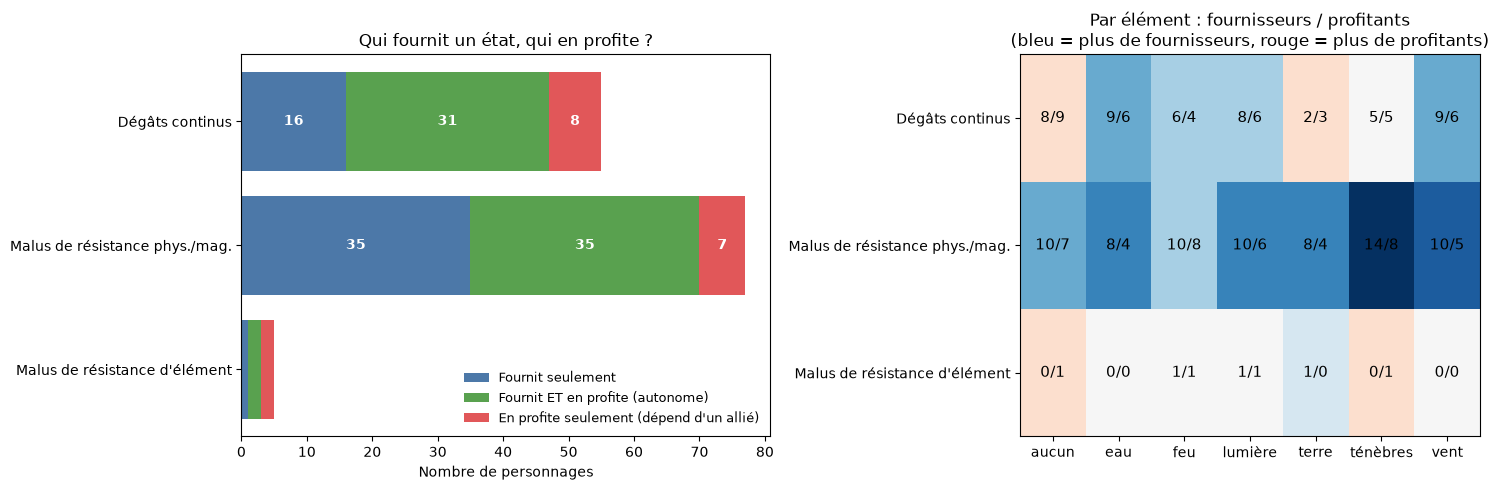

In [57]:
print("Graphique améliorale !\nEn ce moment, certain effet ne sont pas pris en charge")


df_perso = df_perso_complet.filter(~F.col("free"))        # ou df_perso_complet pour tout garder
res_od = graphique_offre_demande(df_perso, niveau=100, avec_incarnation=True)

In [54]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]

def table_complexite(df_eff, df_perso, inclure_rf=False):
    """1 ligne par perso : complexité du kit + indice de puissance (stats niveau 100)."""
    eff = df_eff.select("perso_id", "slot", "effet").distinct().toPandas()
    eff = eff[eff.effet != "Autre"]
    if not inclure_rf:                                    # RF est présent chez presque tous : on l'ignore
        eff = eff[~eff.effet.str.startswith("Recollection Field")]
    cond = eff.effet.str.contains(" \\+ : ")              # effets "Dégâts + : <condition>" = conditionnels
    kit = (eff.groupby("perso_id").effet.nunique().rename("n_effets").to_frame()
              .join(eff[cond].groupby("perso_id").effet.nunique().rename("n_conditionnels"))
              .fillna(0).astype(int))
    st = (df_perso.select("id", "nom_complet", "element", "free",
                          *[F.col(f"stats.lvl_100.{s}").alias(s) for s in STATS]).toPandas()
          .set_index("id"))
    st["principale"] = st[["ATK", "MATK"]].max(axis=1)    # l'ATK ou MATK qui compte pour ce perso
    cols = ["HP", "MP", "principale", "DEF", "MDEF", "CRIT", "SPD"]
    z = (st[cols] - st[cols].mean()) / st[cols].std(ddof=0)
    st["puissance"] = z.mean(axis=1)
    return (st.join(kit).fillna({"n_effets": 0, "n_conditionnels": 0})
              .astype({"n_effets": int, "n_conditionnels": int}))

def _rho(x, y, n_boot=1000, seed=0):
    r = spearmanr(x, y).statistic
    rng = np.random.default_rng(seed); n = len(x); b = []
    xv, yv = np.asarray(x), np.asarray(y)
    for _ in range(n_boot):
        i = rng.integers(0, n, n); b.append(spearmanr(xv[i], yv[i]).statistic)
    return r, np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)

def graphique_complexite(df_eff, df_perso, inclure_rf=False):
    t = table_complexite(df_eff, df_perso, inclure_rf)
    n = len(t)
    print(f"{n} personnages | effets distincts par kit : min {t.n_effets.min()}, "
          f"médiane {t.n_effets.median():.0f}, max {t.n_effets.max()}")
    r, lo, hi = _rho(t.n_effets, t.puissance)
    print(f"Corrélation de Spearman complexité ↔ puissance : {r:+.2f}  (IC95% {lo:+.2f} à {hi:+.2f})")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
    rng = np.random.default_rng(1)
    ax1.scatter(t.n_effets + rng.uniform(-.2, .2, n), t.puissance, s=30, alpha=.6, color="#4c78a8")
    med = t.groupby("n_effets").puissance.agg(["median", "size"])
    med = med[med["size"] >= 5]                          # médiane seulement si >= 5 persos
    ax1.plot(med.index, med["median"], "o-", color="#e15759", lw=2, label="médiane (groupes de ≥5 persos)")
    for k, v in med.iterrows():
        ax1.text(k, ax1.get_ylim()[0], f"n={int(v['size'])}", ha="center", va="bottom", fontsize=8, color="#555")
    ax1.axhline(0, color="#bbb", lw=.7)
    ax1.set_xlabel("Nombre d'effets distincts dans le kit (hors Recollection Field)")
    ax1.set_ylabel("Indice de puissance (moyenne des écarts-types des stats)")
    ax1.set_title(f"Kit plus complexe = stats plus fortes ?  ρ = {r:+.2f} [{lo:+.2f} ; {hi:+.2f}]")
    ax1.legend(frameon=False)

    cols = ["HP", "MP", "principale", "DEF", "MDEF", "CRIT", "SPD"]
    res = []
    for c in cols:
        rr, l, h = _rho(t.n_effets, t[c], n_boot=500); res.append((c, rr, l, h))
    res = pd.DataFrame(res, columns=["stat", "rho", "lo", "hi"]).sort_values("rho")
    ax2.barh(res.stat, res.rho, xerr=[res.rho - res.lo, res.hi - res.rho], color="#76b7b2", capsize=3)
    ax2.axvline(0, color="k", lw=.8)
    ax2.set_xlabel("Corrélation de Spearman avec le nombre d'effets")
    ax2.set_title("Stat par stat (barre = intervalle à 95 %)")
    plt.tight_layout(); plt.show()
    return t

['competence_1', 'competence_2', 'competence_3', 'incarnation'] : 56 effets distincts | phrases non classées (« Autre ») : 0
181 personnages | effets distincts par kit : min 0, médiane 3, max 7
Corrélation de Spearman complexité ↔ puissance : +0.19  (IC95% +0.02 à +0.34)


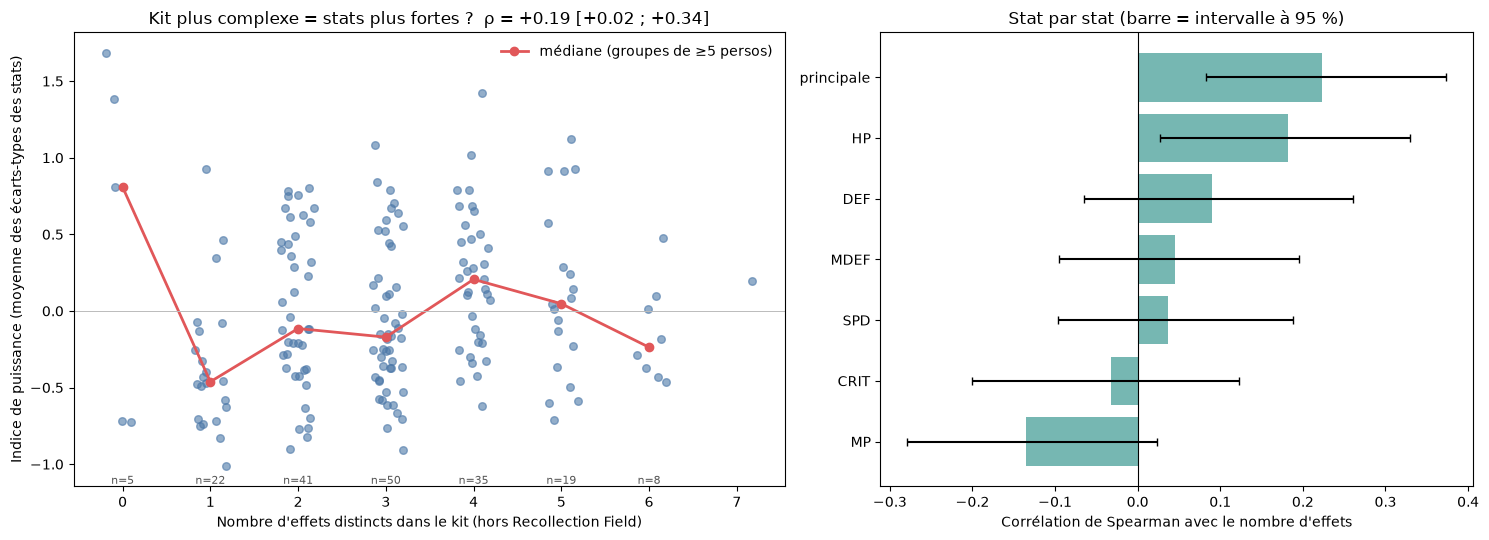

In [56]:
p = F.col("p")
df_perso = df_perso_complet.filter(~F.col("free"))       # ou df_perso_complet pour tout garder
df_eff = construire_effets(SLOTS_COMPETENCES + SLOTS_INCARNATION)   # kit complet (comme dans ton notebook)

t = graphique_complexite(df_eff, df_perso)
# t.sort_values("n_effets").head(10)    # pour voir les kits les plus simples

In [58]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

STATS = ["HP", "MP", "ATK", "MATK", "DEF", "MDEF", "CRIT", "SPD"]
SQ3 = np.sqrt(3) / 2

# ---------- 1) Budget de STATS : attaque / défense / tempo ----------
GROUPES_STATS = {"Attaque": ["principale", "CRIT"], "Défense": ["HP", "DEF", "MDEF"], "Tempo": ["MP", "SPD"]}

def table_budget_stats(df_perso, niveau=100):
    st = (df_perso.select("id", "nom_complet", "element", "free",
                          *[F.col(f"stats.lvl_{niveau}.{s}").alias(s) for s in STATS]).toPandas().set_index("id"))
    st["famille"] = np.where(st.ATK >= st.MATK, "physique", "magique")
    st["principale"] = st[["ATK", "MATK"]].max(axis=1)
    cols = sorted({c for g in GROUPES_STATS.values() for c in g})
    moy = st[cols].mean()
    rel = st[cols] / moy                                   # 1.0 = stat moyenne du groupe de persos affiché
    for g, cs in GROUPES_STATS.items():
        st[g] = rel[cs].mean(axis=1)
    tot = st[list(GROUPES_STATS)].sum(axis=1)
    for g in GROUPES_STATS:
        st["part_" + g] = st[g] / tot
    return st, moy

def projeter_candidat(stats, moy):
    s = pd.Series(stats, dtype=float); s["principale"] = max(s["ATK"], s["MATK"])
    sc = {g: (s[cs] / moy[cs]).mean() for g, cs in GROUPES_STATS.items()}
    t = sum(sc.values()); return [sc[g] / t for g in GROUPES_STATS]

# ---------- 2) Budget de KIT : soi-même / alliés / ennemis ----------
def cible_effet(e):
    """À qui profite / nuit l'effet ? None = ignoré (Recollection Field, Autre, contrepartie, attaque supp.)."""
    if e.startswith("Recollection Field") or e in ("Autre", "Malus en contrepartie", "Attaque supplémentaire"):
        return None
    if " + : " in e or "(soi" in e or e in ("Multiplication Charge/Break (soi)", "Attaque avec coût en HP",
                                             "Absorption de HP", "Contre-attaque", "Provocation"):
        return "Soi-même"
    if "(alliés)" in e or "(cible non précisée)" in e or e in ("Guérison / soin de statut", "Restauration de MP (alliés)"):
        return "Alliés"
    if e.startswith(("Malus", "Réduction")) or e == "Dégâts continus":
        return "Ennemis"
    return None

CIBLES = ["Soi-même", "Alliés", "Ennemis"]

def table_budget_kit(df_eff, min_effets=3):
    eff = df_eff.select("perso_id", "effet").distinct().toPandas()
    eff["cible"] = eff.effet.map(cible_effet)
    eff = eff.dropna(subset=["cible"])
    k = eff.groupby(["perso_id", "cible"]).size().unstack(fill_value=0).reindex(columns=CIBLES, fill_value=0)
    k["n"] = k[CIBLES].sum(axis=1)
    k = k[k.n >= min_effets]                                # trop peu d'effets : la part n'a pas de sens
    for c in CIBLES:
        k["part_" + c] = k[c] / k.n
    return k

# ---------- 3) Triangle zoomé ----------
def _xy(a, b, c):
    s = a + b + c
    return 0.5 * (2 * c + a) / s, SQ3 * a / s            # sommet haut = a ; bas-gauche = b ; bas-droite = c

def _clip(p0, p1, box):
    (x0, y0), (x1, y1) = p0, p1
    xmin, xmax, ymin, ymax = box
    t0, t1 = 0.0, 1.0
    for p, q in [(-(x1 - x0), x0 - xmin), (x1 - x0, xmax - x0), (-(y1 - y0), y0 - ymin), (y1 - y0, ymax - y0)]:
        if p == 0:
            if q < 0: return None
        else:
            r = q / p
            if p < 0: t0 = max(t0, r)
            else: t1 = min(t1, r)
    if t0 > t1: return None
    return (x0 + t0 * (x1 - x0), y0 + t0 * (y1 - y0)), (x0 + t1 * (x1 - x0), y0 + t1 * (y1 - y0))

def triangle(ax, P, noms_axes, couleurs, labels=None, titre="", centre=None, candidat=None, pas=0.05, jitter=0.0):
    """P : tableau (n,3) de parts (a,b,c). Zoom automatique sur les données."""
    xy = np.array([_xy(*p) for p in P])
    xy = xy + np.random.default_rng(0).normal(0, jitter, xy.shape)   # évite que les points identiques se superposent
    mx, my = (xy[:, 0].max() - xy[:, 0].min()) * .18 + .01, (xy[:, 1].max() - xy[:, 1].min()) * .18 + .01
    pts = xy if candidat is None else np.vstack([xy, _xy(*candidat)])
    box = (pts[:, 0].min() - mx, pts[:, 0].max() + mx, pts[:, 1].min() - my, pts[:, 1].max() + my)
    for i, nom in enumerate(noms_axes):                  # grilles : part de l'axe i = k
        for k in np.arange(0.0, 1.0, pas)[1:]:
            ends = []
            for s in (0, 1 - k):
                v = [0, 0, 0]; v[i] = k; v[(i + 1) % 3] = s; v[(i + 2) % 3] = 1 - k - s
                ends.append(_xy(*v))
            seg = _clip(ends[0], ends[1], box)
            if seg is None: continue
            ax.plot([seg[0][0], seg[1][0]], [seg[0][1], seg[1][1]], color="#ddd", lw=.7, zorder=0)
            lab = (max(seg, key=lambda q: q[0]) if i == 0 else
                   min(seg, key=lambda q: q[0]) if i == 1 else min(seg, key=lambda q: q[1]))
            cx0, cy0 = (box[0] + box[1]) / 2, (box[2] + box[3]) / 2
            dx, dy = lab[0] - cx0, lab[1] - cy0; nrm = np.hypot(dx, dy) or 1
            sp_ = 0.025 * max(box[1] - box[0], box[3] - box[2])
            ax.text(lab[0] + dx / nrm * sp_, lab[1] + dy / nrm * sp_, f"{nom} {k:.0%}", fontsize=7,
                    color="#777", ha="center", va="center", clip_on=False)
    for nom, col in couleurs.items():
        m = (labels == nom)
        ax.scatter(xy[m, 0], xy[m, 1], s=30, alpha=.75, color=col, label=f"{nom} ({m.sum()})",
                   edgecolor="white", linewidth=.4, zorder=3)
    if centre is not None:
        cx, cy = _xy(*centre); ax.scatter([cx], [cy], marker="+", s=200, color="k", zorder=4)
        ax.text(cx, cy, "  moyenne", fontsize=8, va="bottom")
    if candidat is not None:
        cx, cy = _xy(*candidat)
        ax.scatter([cx], [cy], marker="*", s=380, color="gold", edgecolor="k", zorder=5, label="Candidat")
    ax.set_xlim(box[0], box[1]); ax.set_ylim(box[2], box[3]); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)
    ax.set_title(titre, fontsize=11, pad=22)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    return xy

def graphique_triangles(df_perso, df_eff, niveau=100, couleur="famille", stats_candidat=None):
    st, moy = table_budget_stats(df_perso, niveau)
    kit = table_budget_kit(df_eff)
    parts = ["part_" + g for g in GROUPES_STATS]
    print(f"{len(st)} persos (stats) | {len(kit)} persos avec ≥3 effets classés (kit)\n")
    print("Part du budget de stats (moyenne ; min – max) :")
    for g in GROUPES_STATS:
        v = st["part_" + g]; print(f"  {g:8s} {v.mean():.1%}  ({v.min():.1%} – {v.max():.1%})")
    print("\nPart du kit (moyenne ; min – max) :")
    for c in CIBLES:
        v = kit["part_" + c]; print(f"  {c:9s} {v.mean():.1%}  ({v.min():.1%} – {v.max():.1%})")

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7))
    cand = projeter_candidat(stats_candidat, moy) if stats_candidat else None
    pal = {"physique": "#e8833a", "magique": "#4c78a8", "True": "#999999", "False": "#59a14f"}
    lab_s = st["free"].astype(str).values if couleur == "free" else st["famille"].values
    print("\nÉcart-type des parts de stats : " + ", ".join(f"{g} {st['part_'+g].std():.1%}" for g in GROUPES_STATS))
    triangle(a1, st[parts].values, list(GROUPES_STATS), {k: v for k, v in pal.items() if k in set(lab_s)},
             lab_s, "Budget de STATS : où va la force du perso ?\n(attaque = ATK/MATK + CRIT · défense = HP+DEF+MDEF · tempo = MP+SPD)",
             centre=st[parts].mean().values, candidat=cand, pas=0.02)
    kj = kit.join(st[["famille", "free"]], how="inner")
    lab_k = kj["free"].astype(str).values if couleur == "free" else kj["famille"].values
    triangle(a2, kj[["part_" + c for c in CIBLES]].values, CIBLES, {k: v for k, v in pal.items() if k in set(lab_k)},
             lab_k, "Budget de KIT : à qui s'adressent les effets ?\n(part d'effets distincts : soi-même / alliés / ennemis)",
             centre=kj[["part_" + c for c in CIBLES]].mean().values, pas=0.1, jitter=0.012)
    plt.tight_layout(); plt.show()
    return st, kit

['competence_1', 'competence_2', 'competence_3', 'incarnation'] : 56 effets distincts | phrases non classées (« Autre ») : 0
181 persos (stats) | 110 persos avec ≥3 effets classés (kit)

Part du budget de stats (moyenne ; min – max) :
  Attaque  33.3%  (30.2% – 36.0%)
  Défense  33.3%  (29.8% – 38.7%)
  Tempo    33.3%  (29.5% – 36.1%)

Part du kit (moyenne ; min – max) :
  Soi-même  45.6%  (0.0% – 100.0%)
  Alliés    19.1%  (0.0% – 80.0%)
  Ennemis   35.3%  (0.0% – 100.0%)

Écart-type des parts de stats : Attaque 1.0%, Défense 1.2%, Tempo 1.0%


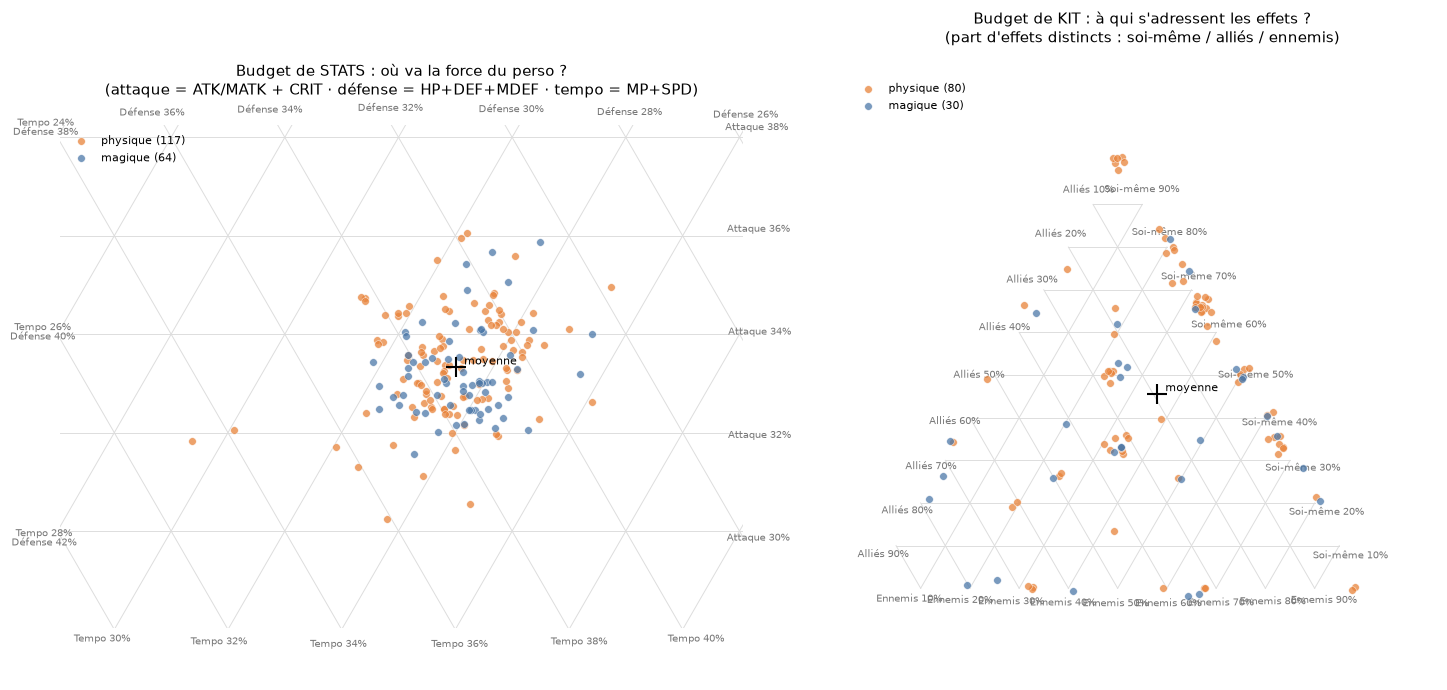

In [59]:
df_perso = df_perso_complet.filter(~F.col("free"))         # ou df_perso_complet pour tout garder
df_eff = construire_effets(SLOTS_COMPETENCES + SLOTS_INCARNATION)

st, kit = graphique_triangles(df_perso, df_eff)            # couleur="free" pour colorier free / non free

# Placer un candidat :
# graphique_triangles(df_perso, df_eff, stats_candidat=dict(HP=7500, MP=280, ATK=2900, MATK=2200,
#                                                           DEF=1450, MDEF=1400, CRIT=700, SPD=320))